In [1]:

# ============================================================
# CREDIT RISK PORTFOLIO ANALYTICS
# STEP 1: LOAD DATA + INITIAL DATA QUALITY AUDIT
# Platform: Google Colab
#
# Input files:
#   customers.csv
#   loan_accounts.csv
#   bureau_credit.csv
#   repayment_history.csv
#   collections_events.csv
#   DATA_DICTIONARY.md (optional)
#
# This step does NOT train models or modify the original data.
# ============================================================

import os
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# ------------------------------------------------------------
# 1. Upload the original files
# ------------------------------------------------------------

from google.colab import files

print("Upload the five original CSV files.")
print("You may also upload DATA_DICTIONARY.md.")
uploaded_files = files.upload()

print(f"\nFiles uploaded: {len(uploaded_files)}")

# ------------------------------------------------------------
# 2. Resolve filenames robustly
# Handles names such as customers (1).csv or customers(1).csv.
# ------------------------------------------------------------

def normalize_filename(filename):
    name = Path(filename).name.lower()
    stem = Path(name).stem
    extension = Path(name).suffix

    # Remove duplicate-upload suffixes such as " (1)" or "(2)".
    stem = re.sub(r"\s*\(\d+\)$", "", stem).strip()

    return stem + extension


uploaded_lookup = {}

for filename in uploaded_files.keys():
    normalized = normalize_filename(filename)
    uploaded_lookup[normalized] = filename

required_files = {
    "customers.csv": "customers",
    "loan_accounts.csv": "loan_accounts",
    "bureau_credit.csv": "bureau_credit",
    "repayment_history.csv": "repayment_history",
    "collections_events.csv": "collections_events",
}

missing_files = [
    filename
    for filename in required_files
    if filename not in uploaded_lookup
]

if missing_files:
    raise FileNotFoundError(
        "The following required files were not uploaded:\n"
        + "\n".join(missing_files)
        + "\n\nUpload the missing files and rerun this cell."
    )

# ------------------------------------------------------------
# 3. Load all five datasets
# ------------------------------------------------------------

data = {}

for filename, variable_name in required_files.items():
    actual_filename = uploaded_lookup[filename]

    df = pd.read_csv(actual_filename, low_memory=False)
    df.columns = df.columns.str.strip()

    data[variable_name] = df

    print(
        f"Loaded {actual_filename}: "
        f"{df.shape[0]:,} rows x {df.shape[1]:,} columns"
    )

customers = data["customers"]
loan_accounts = data["loan_accounts"]
bureau_credit = data["bureau_credit"]
repayment_history = data["repayment_history"]
collections_events = data["collections_events"]

# Load the data dictionary if it was uploaded.
dictionary_filename = uploaded_lookup.get("data_dictionary.md")

if dictionary_filename:
    print(f"\nData dictionary found: {dictionary_filename}")
    with open(dictionary_filename, "r", encoding="utf-8") as file:
        data_dictionary_text = file.read()

    print("\nData dictionary preview:")
    print(data_dictionary_text[:3000])
else:
    data_dictionary_text = None
    print("\nDATA_DICTIONARY.md was not uploaded. Continuing without it.")

# ------------------------------------------------------------
# 4. Confirm expected columns
# ------------------------------------------------------------

expected_columns = {
    "customers": [
        "customer_id", "age", "gender", "marital_status",
        "education_level", "employment_type", "occupation_sector",
        "years_employed", "annual_income", "region", "city_tier",
        "num_dependents", "housing_type", "years_at_residence",
        "customer_since"
    ],
    "loan_accounts": [
        "account_id", "customer_id", "loan_type", "loan_purpose",
        "loan_amount", "interest_rate_pct", "tenure_months",
        "origination_date", "disbursal_channel", "collateral_flag",
        "target_default"
    ],
    "bureau_credit": [
        "bureau_id", "customer_id", "credit_type", "lender_category",
        "sanctioned_amount", "outstanding_amount", "account_status",
        "days_past_due", "date_opened", "date_closed"
    ],
    "repayment_history": [
        "account_id", "payment_month", "emi_due", "emi_paid",
        "days_past_due", "payment_status", "outstanding_balance"
    ],
    "collections_events": [
        "collection_event_id", "account_id", "event_date",
        "action_type", "outcome", "amount_recovered"
    ],
}

print("\n" + "=" * 80)
print("COLUMN VALIDATION")
print("=" * 80)

column_issues = []

for table_name, expected in expected_columns.items():
    df = data[table_name]

    missing = sorted(set(expected) - set(df.columns))
    extra = sorted(set(df.columns) - set(expected))

    print(f"\n{table_name}:")
    print("  Missing expected columns:", missing if missing else "None")
    print("  Additional columns:", extra if extra else "None")

    if missing:
        column_issues.append({
            "table": table_name,
            "issue": "Missing expected columns",
            "details": ", ".join(missing)
        })

if column_issues:
    print(
        "\nWARNING: Resolve the missing-column issues before proceeding "
        "to feature engineering."
    )

# ------------------------------------------------------------
# 5. Dataset shapes and data types
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("DATASET OVERVIEW")
print("=" * 80)

overview_rows = []

for table_name, df in data.items():
    overview_rows.append({
        "table": table_name,
        "rows": len(df),
        "columns": len(df.columns),
        "duplicate_full_rows": int(df.duplicated().sum()),
        "total_missing_cells": int(df.isna().sum().sum()),
        "missing_percentage": round(
            df.isna().sum().sum() / max(df.size, 1) * 100, 3
        )
    })

overview_df = pd.DataFrame(overview_rows)
display(overview_df)

print("\nColumn data types:")
for table_name, df in data.items():
    print(f"\n--- {table_name} ---")
    print(df.dtypes.to_string())

# ------------------------------------------------------------
# 6. Missing-value audit
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("MISSING-VALUE AUDIT")
print("=" * 80)

missing_rows = []

for table_name, df in data.items():
    missing_counts = df.isna().sum()

    for column in df.columns:
        count = int(missing_counts[column])

        if count > 0:
            missing_rows.append({
                "table": table_name,
                "column": column,
                "missing_count": count,
                "missing_percentage": round(
                    count / len(df) * 100, 3
                ) if len(df) else 0
            })

missing_audit_df = pd.DataFrame(
    missing_rows,
    columns=[
        "table", "column", "missing_count", "missing_percentage"
    ]
)

if not missing_audit_df.empty:
    missing_audit_df = missing_audit_df.sort_values(
        ["table", "missing_count"],
        ascending=[True, False]
    )
    display(missing_audit_df)
else:
    print("No missing values found.")

# ------------------------------------------------------------
# 7. Primary-key and relationship checks
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("KEY AND RELATIONSHIP AUDIT")
print("=" * 80)

key_definitions = {
    "customers": ["customer_id"],
    "loan_accounts": ["account_id"],
    "bureau_credit": ["bureau_id"],
    "collections_events": ["collection_event_id"],
}

key_audit_rows = []

for table_name, keys in key_definitions.items():
    df = data[table_name]

    for key in keys:
        if key not in df.columns:
            continue

        key_audit_rows.append({
            "table": table_name,
            "key": key,
            "null_key_rows": int(df[key].isna().sum()),
            "duplicate_key_rows": int(
                df.duplicated(subset=[key], keep=False).sum()
            ),
            "unique_key_values": int(df[key].nunique(dropna=True))
        })

key_audit_df = pd.DataFrame(key_audit_rows)
display(key_audit_df)

relationship_rows = []

# Loan accounts -> customers
if {"customer_id"}.issubset(customers.columns) and {
    "customer_id"
}.issubset(loan_accounts.columns):

    known_customer_ids = set(customers["customer_id"].dropna())

    unmatched = ~loan_accounts["customer_id"].isin(known_customer_ids)

    relationship_rows.append({
        "relationship": "loan_accounts -> customers",
        "rows_checked": len(loan_accounts),
        "unmatched_rows": int(unmatched.sum()),
        "unmatched_percentage": round(unmatched.mean() * 100, 3)
    })

# Bureau records -> customers
if "customer_id" in customers.columns and "customer_id" in bureau_credit.columns:

    known_customer_ids = set(customers["customer_id"].dropna())
    unmatched = ~bureau_credit["customer_id"].isin(known_customer_ids)

    relationship_rows.append({
        "relationship": "bureau_credit -> customers",
        "rows_checked": len(bureau_credit),
        "unmatched_rows": int(unmatched.sum()),
        "unmatched_percentage": round(unmatched.mean() * 100, 3)
    })

# Repayment history -> loan accounts
if "account_id" in loan_accounts.columns and "account_id" in repayment_history.columns:

    known_account_ids = set(loan_accounts["account_id"].dropna())
    unmatched = ~repayment_history["account_id"].isin(known_account_ids)

    relationship_rows.append({
        "relationship": "repayment_history -> loan_accounts",
        "rows_checked": len(repayment_history),
        "unmatched_rows": int(unmatched.sum()),
        "unmatched_percentage": round(unmatched.mean() * 100, 3)
    })

# Collections events -> loan accounts
if "account_id" in loan_accounts.columns and "account_id" in collections_events.columns:

    known_account_ids = set(loan_accounts["account_id"].dropna())
    unmatched = ~collections_events["account_id"].isin(known_account_ids)

    relationship_rows.append({
        "relationship": "collections_events -> loan_accounts",
        "rows_checked": len(collections_events),
        "unmatched_rows": int(unmatched.sum()),
        "unmatched_percentage": round(unmatched.mean() * 100, 3)
    })

relationship_audit_df = pd.DataFrame(relationship_rows)
display(relationship_audit_df)

# ------------------------------------------------------------
# 8. Target validation
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("TARGET AUDIT: target_default")
print("=" * 80)

if "target_default" not in loan_accounts.columns:
    raise KeyError(
        "target_default was not found in loan_accounts.csv. "
        "Check the column names before proceeding."
    )

target = loan_accounts["target_default"]

print("Target data type:", target.dtype)
print("Target missing values:", int(target.isna().sum()))
print("Target unique values:", sorted(target.dropna().unique().tolist(), key=str))

print("\nTarget frequency:")
display(
    target.value_counts(dropna=False)
    .rename_axis("target_default")
    .reset_index(name="count")
)

print("\nTarget distribution (%):")
display(
    (
        target.value_counts(normalize=True, dropna=False) * 100
    )
    .round(3)
    .rename_axis("target_default")
    .reset_index(name="percentage")
)

valid_target_values = set(target.dropna().unique()).issubset({0, 1})

print("\nIs the non-missing target binary 0/1?", valid_target_values)

if not valid_target_values:
    print(
        "WARNING: target_default contains values other than 0 and 1. "
        "Investigate these before model training."
    )

# ------------------------------------------------------------
# 9. Date parsing and date-range audit
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("DATE AUDIT")
print("=" * 80)

date_columns = {
    "customers": ["customer_since"],
    "loan_accounts": ["origination_date"],
    "bureau_credit": ["date_opened", "date_closed"],
    "collections_events": ["event_date"],
}

date_audit_rows = []

for table_name, columns in date_columns.items():
    df = data[table_name]

    for column in columns:
        if column not in df.columns:
            continue

        parsed_dates = pd.to_datetime(df[column], errors="coerce")

        original_nonmissing = int(df[column].notna().sum())
        parse_failures = int(
            (df[column].notna() & parsed_dates.isna()).sum()
        )

        date_audit_rows.append({
            "table": table_name,
            "column": column,
            "original_nonmissing": original_nonmissing,
            "parse_failures": parse_failures,
            "minimum_date": parsed_dates.min(),
            "maximum_date": parsed_dates.max()
        })

        # Convert the in-memory data to datetime for later audits.
        df[column] = parsed_dates

date_audit_df = pd.DataFrame(date_audit_rows)
display(date_audit_df)

# ------------------------------------------------------------
# 10. Repayment-history structure
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("REPAYMENT HISTORY AUDIT")
print("=" * 80)

required_repayment_cols = {
    "account_id", "payment_month", "emi_due", "emi_paid",
    "days_past_due", "payment_status", "outstanding_balance"
}

if required_repayment_cols.issubset(repayment_history.columns):

    repayment_history["payment_month"] = pd.to_numeric(
        repayment_history["payment_month"], errors="coerce"
    )

    print("Unique accounts in repayment history:",
          repayment_history["account_id"].nunique())

    print("\nPayment-month distribution:")
    display(
        repayment_history["payment_month"]
        .value_counts(dropna=False)
        .sort_index()
        .rename_axis("payment_month")
        .reset_index(name="record_count")
    )

    records_per_account = repayment_history.groupby(
        "account_id"
    ).size()

    print("\nRecords per account summary:")
    display(records_per_account.describe().to_frame("records_per_account"))

    duplicate_account_months = repayment_history.duplicated(
        subset=["account_id", "payment_month"],
        keep=False
    )

    print(
        "\nRows belonging to duplicate account-month combinations:",
        int(duplicate_account_months.sum())
    )

    repayment_month_range = repayment_history.groupby(
        "account_id"
    )["payment_month"].agg(["min", "max", "count"])

    print("\nAccounts with records outside months 1-12:",
          int(
              (
                  (repayment_month_range["min"] < 1)
                  | (repayment_month_range["max"] > 12)
              ).sum()
          ))

    print("\nPayment status distribution:")
    display(
        repayment_history["payment_status"]
        .value_counts(dropna=False)
        .rename_axis("payment_status")
        .reset_index(name="count")
    )

else:
    print(
        "Some expected repayment columns are missing. "
        "Review the column validation output."
    )

# ------------------------------------------------------------
# 11. Bureau timing audit against loan origination
# Important:
# One customer can have multiple loans. A bureau record opened
# after one loan may still have existed before another loan.
# This is a screening audit, not proof that every flagged record
# is leakage. We will rebuild features using cutoff-aware filters.
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("BUREAU TIMING SCREEN")
print("=" * 80)

if (
    {"customer_id", "origination_date"}.issubset(loan_accounts.columns)
    and {"customer_id", "date_opened", "date_closed"}.issubset(
        bureau_credit.columns
    )
):

    loan_date_map = loan_accounts[
        ["account_id", "customer_id", "origination_date"]
    ].copy()

    bureau_date_check = loan_date_map.merge(
        bureau_credit[
            ["customer_id", "date_opened", "date_closed"]
        ],
        on="customer_id",
        how="left",
        validate="many_to_many"
    )

    has_bureau_record = bureau_date_check["date_opened"].notna()

    opened_after_origination = (
        has_bureau_record
        & (bureau_date_check["date_opened"]
           > bureau_date_check["origination_date"])
    )

    closed_after_origination = (
        bureau_date_check["date_closed"].notna()
        & (bureau_date_check["date_closed"]
           > bureau_date_check["origination_date"])
    )

    bureau_timing_summary = pd.DataFrame({
        "check": [
            "Loan-to-bureau customer-loan pairs",
            "Pairs with a matched bureau opening date",
            "Pairs where bureau date_opened is after loan origination",
            "Pairs where bureau date_closed is after loan origination"
        ],
        "count": [
            len(bureau_date_check),
            int(has_bureau_record.sum()),
            int(opened_after_origination.sum()),
            int(closed_after_origination.sum())
        ]
    })

    display(bureau_timing_summary)

    if has_bureau_record.sum() > 0:
        print(
            "\nPercentage of matched pairs with date_opened after "
            "origination:",
            round(
                opened_after_origination.sum()
                / has_bureau_record.sum() * 100,
                2
            ),
            "%"
        )

    print(
        "\nInterpretation: These are pair-level timing flags. "
        "They do not establish the exact date the bureau balance, "
        "DPD or account status was reported. We must not use "
        "future-opened accounts in cutoff-specific bureau features."
    )

else:
    print(
        "Cannot perform the bureau timing screen because expected "
        "date or customer columns are missing."
    )

# ------------------------------------------------------------
# 12. Preliminary repayment vs target comparison
# Descriptive only: this does NOT establish when target_default
# occurred or prove that repayment features are valid predictors.
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("DESCRIPTIVE TARGET-REPAYMENT COMPARISON")
print("=" * 80)

if (
    {"account_id", "target_default"}.issubset(loan_accounts.columns)
    and {"account_id", "payment_month", "days_past_due",
         "payment_status", "emi_due", "emi_paid"}.issubset(
             repayment_history.columns
         )
):

    target_map = loan_accounts[
        ["account_id", "target_default"]
    ].drop_duplicates("account_id")

    repayment_target = repayment_history.merge(
        target_map,
        on="account_id",
        how="left",
        validate="many_to_one"
    )

    repayment_target["days_past_due"] = pd.to_numeric(
        repayment_target["days_past_due"], errors="coerce"
    )
    repayment_target["emi_due"] = pd.to_numeric(
        repayment_target["emi_due"], errors="coerce"
    )
    repayment_target["emi_paid"] = pd.to_numeric(
        repayment_target["emi_paid"], errors="coerce"
    )

    repayment_target["is_missed_status"] = (
        repayment_target["payment_status"]
        .astype("string")
        .str.strip()
        .str.lower()
        .eq("missed")
        .astype(int)
    )

    repayment_target["is_late_status"] = (
        repayment_target["payment_status"]
        .astype("string")
        .str.strip()
        .str.lower()
        .eq("late")
        .astype(int)
    )

    # Keep rows with valid binary targets for this descriptive summary.
    valid_rows = repayment_target[
        repayment_target["target_default"].isin([0, 1])
    ].copy()

    repayment_by_account = valid_rows.groupby(
        ["account_id", "target_default"]
    ).agg(
        repayment_record_count=("payment_month", "count"),
        max_days_past_due=("days_past_due", "max"),
        mean_days_past_due=("days_past_due", "mean"),
        missed_status_count=("is_missed_status", "sum"),
        late_status_count=("is_late_status", "sum"),
        total_emi_due=("emi_due", "sum"),
        total_emi_paid=("emi_paid", "sum")
    ).reset_index()

    repayment_by_account["paid_to_due_ratio"] = np.where(
        repayment_by_account["total_emi_due"] > 0,
        repayment_by_account["total_emi_paid"]
        / repayment_by_account["total_emi_due"],
        np.nan
    )

    descriptive_columns = [
        "repayment_record_count",
        "max_days_past_due",
        "mean_days_past_due",
        "missed_status_count",
        "late_status_count",
        "paid_to_due_ratio"
    ]

    target_repayment_summary = repayment_by_account.groupby(
        "target_default"
    )[descriptive_columns].mean().round(3)

    print(
        "Average account-level repayment summaries by target label "
        "(descriptive, not causal):"
    )
    display(target_repayment_summary)

    print(
        "\nImportant: A relationship between repayment behavior and "
        "target_default does not tell us whether the repayment records "
        "occurred before the target event."
    )

# ------------------------------------------------------------
# 13. Save the audit outputs
# ------------------------------------------------------------

OUTPUT_DIR = "/content/credit_risk_step1_audit"
os.makedirs(OUTPUT_DIR, exist_ok=True)

overview_df.to_csv(
    os.path.join(OUTPUT_DIR, "dataset_overview.csv"), index=False
)

missing_audit_df.to_csv(
    os.path.join(OUTPUT_DIR, "missing_value_audit.csv"), index=False
)

key_audit_df.to_csv(
    os.path.join(OUTPUT_DIR, "key_audit.csv"), index=False
)

relationship_audit_df.to_csv(
    os.path.join(OUTPUT_DIR, "relationship_audit.csv"), index=False
)

date_audit_df.to_csv(
    os.path.join(OUTPUT_DIR, "date_audit.csv"), index=False
)

if "bureau_timing_summary" in globals():
    bureau_timing_summary.to_csv(
        os.path.join(OUTPUT_DIR, "bureau_timing_screen.csv"),
        index=False
    )

if "target_repayment_summary" in globals():
    target_repayment_summary.to_csv(
        os.path.join(OUTPUT_DIR, "target_repayment_summary.csv")
    )

# Save the data dictionary as an audit reference if available.
if data_dictionary_text:
    with open(
        os.path.join(OUTPUT_DIR, "DATA_DICTIONARY.md"),
        "w",
        encoding="utf-8"
    ) as file:
        file.write(data_dictionary_text)

print("\n" + "=" * 80)
print("STEP 1 COMPLETE")
print("=" * 80)
print("Audit outputs saved in:", OUTPUT_DIR)
print("Original source files were not overwritten.")
print("\nDo not train models yet. Review the audit results first.")


Upload the five original CSV files.
You may also upload DATA_DICTIONARY.md.


Saving bureau_credit.csv to bureau_credit.csv
Saving collections_events.csv to collections_events.csv
Saving customers.csv to customers.csv
Saving DATA_DICTIONARY.md to DATA_DICTIONARY.md
Saving loan_accounts.csv to loan_accounts.csv
Saving repayment_history.csv to repayment_history.csv

Files uploaded: 6
Loaded customers.csv: 10,000 rows x 15 columns
Loaded loan_accounts.csv: 14,685 rows x 11 columns
Loaded bureau_credit.csv: 22,979 rows x 10 columns
Loaded repayment_history.csv: 176,220 rows x 7 columns
Loaded collections_events.csv: 8,635 rows x 6 columns

Data dictionary found: DATA_DICTIONARY.md

Data dictionary preview:
# Credit Risk Portfolio — Synthetic Dataset

5 interlinked tables covering **10,000 customers** and their loan accounts,
external credit history, repayment behavior, and collections activity.
All data is synthetically generated but designed to mimic realistic
distributions, correlations, and messiness found in real banking data.

## Table Overview

| File | Grain 

,table,rows,columns,duplicate_full_rows,total_missing_cells,missing_percentage
0,customers,10000,15,0,1500,1.000
1,loan_accounts,14685,11,0,294,0.182
2,bureau_credit,22979,10,0,11932,5.193
3,repayment_history,176220,7,0,0,0.000
4,collections_events,8635,6,0,0,0.000



Column data types:

--- customers ---
customer_id            object
age                     int64
gender                 object
marital_status         object
education_level        object
employment_type        object
occupation_sector      object
years_employed        float64
annual_income         float64
region                 object
city_tier              object
num_dependents        float64
housing_type           object
years_at_residence    float64
customer_since         object

--- loan_accounts ---
account_id            object
customer_id           object
loan_type             object
loan_purpose          object
loan_amount          float64
interest_rate_pct    float64
tenure_months          int64
origination_date      object
disbursal_channel     object
collateral_flag        int64
target_default         int64

--- bureau_credit ---
bureau_id              object
customer_id            object
credit_type            object
lender_category        object
sanctioned_amount     floa

,table,column,missing_count,missing_percentage
5,bureau_credit,date_closed,11243,48.927
4,bureau_credit,days_past_due,689,2.998
0,customers,years_employed,500,5.000
1,customers,num_dependents,500,5.000
2,customers,years_at_residence,500,5.000
3,loan_accounts,interest_rate_pct,294,2.002


...


BUREAU TIMING SCREEN


,check,count
0,Loan-to-bureau customer-loan pairs,35226
1,Pairs with a matched bureau opening date,33764
2,Pairs where bureau date_opened is after loan o...,21104
3,Pairs where bureau date_closed is after loan o...,14287



Percentage of matched pairs with date_opened after origination: 62.5 %

Interpretation: These are pair-level timing flags. They do not establish the exact date the bureau balance, DPD or account status was reported. We must not use future-opened accounts in cutoff-specific bureau features.

DESCRIPTIVE TARGET-REPAYMENT COMPARISON
Average account-level repayment summaries by target label (descriptive, not causal):


,repayment_record_count,max_days_past_due,mean_days_past_due,missed_status_count,late_status_count,paid_to_due_ratio
target_default,,,,,,
0,12.0,32.290,4.169,0.515,1.338,0.957
1,12.0,41.147,6.044,0.788,1.762,0.934



Important: A relationship between repayment behavior and target_default does not tell us whether the repayment records occurred before the target event.

STEP 1 COMPLETE
Audit outputs saved in: /content/credit_risk_step1_audit
Original source files were not overwritten.

Do not train models yet. Review the audit results first.


In [2]:

# ============================================================
# CREDIT RISK PORTFOLIO ANALYTICS
# STEP 2: TARGET DEFINITION + DATA LEAKAGE AUDIT
#
# Uses the DataFrames created in Step 1:
# customers, loan_accounts, bureau_credit,
# repayment_history, collections_events
#
# This cell does not train models or change the target.
# ============================================================

import os
import numpy as np
import pandas as pd
from IPython.display import display

OUTPUT_DIR = "/content/credit_risk_step2_audit"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Create audit-safe working copies
# ------------------------------------------------------------

loans = loan_accounts.copy()
bureau = bureau_credit.copy()
repayments = repayment_history.copy()
collections = collections_events.copy()

loans["origination_date"] = pd.to_datetime(
    loans["origination_date"], errors="coerce"
)

bureau["date_opened"] = pd.to_datetime(
    bureau["date_opened"], errors="coerce"
)
bureau["date_closed"] = pd.to_datetime(
    bureau["date_closed"], errors="coerce"
)

collections["event_date"] = pd.to_datetime(
    collections["event_date"], errors="coerce"
)

repayments["payment_month"] = pd.to_numeric(
    repayments["payment_month"], errors="coerce"
)

for col in [
    "days_past_due", "emi_due", "emi_paid", "outstanding_balance"
]:
    repayments[col] = pd.to_numeric(
        repayments[col], errors="coerce"
    )

loans["target_default"] = pd.to_numeric(
    loans["target_default"], errors="coerce"
)

print("=" * 80)
print("STEP 2: TARGET AND LEAKAGE AUDIT")
print("=" * 80)
print("Loan accounts:", len(loans))
print("Target missing:", int(loans["target_default"].isna().sum()))
print("Target values:", sorted(
    loans["target_default"].dropna().unique().tolist()
))

# ------------------------------------------------------------
# 2. Audit bureau records against each loan's origination date
#
# A bureau account opened after loan origination must not be
# included in an origination-time bureau aggregate.
#
# NOTE:
# date_opened does not establish when outstanding balance,
# days past due, or account status was reported.
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("2A. BUREAU TIMING AUDIT")
print("=" * 80)

loan_dates = loans[
    ["account_id", "customer_id", "origination_date"]
].copy()

bureau_pairs = loan_dates.merge(
    bureau,
    on="customer_id",
    how="left",
    suffixes=("_loan", "_bureau")
)

matched = bureau_pairs["bureau_id"].notna()

opened_after_origination = (
    matched
    & bureau_pairs["date_opened"].notna()
    & (
        bureau_pairs["date_opened"]
        > bureau_pairs["origination_date"]
    )
)

opened_on_or_before_origination = (
    matched
    & bureau_pairs["date_opened"].notna()
    & (
        bureau_pairs["date_opened"]
        <= bureau_pairs["origination_date"]
    )
)

closed_after_origination = (
    matched
    & bureau_pairs["date_closed"].notna()
    & (
        bureau_pairs["date_closed"]
        > bureau_pairs["origination_date"]
    )
)

bureau_audit = pd.DataFrame([
    {
        "check": "Loan-bureau record pairs",
        "count": len(bureau_pairs)
    },
    {
        "check": "Pairs with a matched bureau record",
        "count": int(matched.sum())
    },
    {
        "check": "Bureau accounts opened on/before origination",
        "count": int(opened_on_or_before_origination.sum())
    },
    {
        "check": "Bureau accounts opened after origination",
        "count": int(opened_after_origination.sum())
    },
    {
        "check": "Bureau accounts with closure after origination",
        "count": int(closed_after_origination.sum())
    }
])

display(bureau_audit)

bureau_audit.to_csv(
    os.path.join(OUTPUT_DIR, "bureau_timing_audit.csv"),
    index=False
)

# ------------------------------------------------------------
# 3. Identify customers with multiple loans
#
# Important because a bureau record may be too late for one loan
# but valid for a later loan belonging to the same customer.
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("2B. CUSTOMER LOAN HISTORY")
print("=" * 80)

customer_loan_counts = loans.groupby("customer_id").agg(
    loan_count=("account_id", "nunique"),
    first_origination=("origination_date", "min"),
    last_origination=("origination_date", "max")
).reset_index()

print("Customers with multiple loan accounts:",
      int((customer_loan_counts["loan_count"] > 1).sum()))

display(
    customer_loan_counts["loan_count"]
    .value_counts()
    .sort_index()
    .rename_axis("number_of_loans")
    .reset_index(name="number_of_customers")
)

customer_loan_counts.to_csv(
    os.path.join(OUTPUT_DIR, "customer_loan_counts.csv"),
    index=False
)

# ------------------------------------------------------------
# 4. Audit repayment behavior by month and target label
#
# This measures association, not causal direction or target timing.
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("2C. MONTHLY REPAYMENT PATTERNS BY TARGET")
print("=" * 80)

repayments["payment_status_clean"] = (
    repayments["payment_status"]
    .astype("string")
    .str.strip()
    .str.lower()
)

repayments["is_missed"] = (
    repayments["payment_status_clean"] == "missed"
).astype(int)

repayments["is_late"] = (
    repayments["payment_status_clean"] == "late"
).astype(int)

repayments["is_ontime"] = (
    repayments["payment_status_clean"] == "on-time"
).astype(int)

repayment_with_target = repayments.merge(
    loans[["account_id", "target_default"]],
    on="account_id",
    how="left",
    validate="many_to_one"
)

monthly_summary = repayment_with_target.groupby(
    ["target_default", "payment_month"]
).agg(
    account_month_records=("account_id", "size"),
    mean_dpd=("days_past_due", "mean"),
    max_dpd=("days_past_due", "max"),
    missed_rate=("is_missed", "mean"),
    late_rate=("is_late", "mean"),
    ontime_rate=("is_ontime", "mean"),
    total_emi_due=("emi_due", "sum"),
    total_emi_paid=("emi_paid", "sum")
).reset_index()

monthly_summary["missed_rate_pct"] = (
    monthly_summary["missed_rate"] * 100
).round(2)

monthly_summary["late_rate_pct"] = (
    monthly_summary["late_rate"] * 100
).round(2)

monthly_summary["ontime_rate_pct"] = (
    monthly_summary["ontime_rate"] * 100
).round(2)

display(monthly_summary.round(3))

monthly_summary.to_csv(
    os.path.join(OUTPUT_DIR, "monthly_repayment_by_target.csv"),
    index=False
)

# ------------------------------------------------------------
# 5. Compare repayment summaries for months 1-3 vs months 4-12
#
# This is a diagnostic only. It does not prove that target_default
# means default occurred after month 3.
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("2D. EARLY VS LATER REPAYMENT COMPARISON")
print("=" * 80)

repayments["repayment_period"] = np.select(
    [
        repayments["payment_month"].between(1, 3),
        repayments["payment_month"].between(4, 12)
    ],
    [
        "Months 1-3",
        "Months 4-12"
    ],
    default="Outside expected range"
)

period_data = repayments.merge(
    loans[["account_id", "target_default"]],
    on="account_id",
    how="left",
    validate="many_to_one"
)

period_summary = period_data.groupby(
    ["target_default", "repayment_period"]
).agg(
    records=("account_id", "size"),
    mean_dpd=("days_past_due", "mean"),
    max_dpd=("days_past_due", "max"),
    missed_count=("is_missed", "sum"),
    late_count=("is_late", "sum"),
    mean_emi_due=("emi_due", "mean"),
    mean_emi_paid=("emi_paid", "mean"),
    mean_outstanding_balance=("outstanding_balance", "mean")
).reset_index()

display(period_summary.round(3))

period_summary.to_csv(
    os.path.join(OUTPUT_DIR, "early_vs_later_repayment.csv"),
    index=False
)

# ------------------------------------------------------------
# 6. Account-level features from months 1-3 and months 4-12
#
# These are for investigating the label only.
# They are NOT being merged into a training dataset here.
# ------------------------------------------------------------

def build_period_features(df, start_month, end_month, prefix):
    part = df[
        df["payment_month"].between(start_month, end_month)
    ].copy()

    part["is_missed"] = (
        part["payment_status_clean"] == "missed"
    ).astype(int)

    part["is_late"] = (
        part["payment_status_clean"] == "late"
    ).astype(int)

    part["is_ontime"] = (
        part["payment_status_clean"] == "on-time"
    ).astype(int)

    part["emi_shortfall"] = (
        part["emi_due"] - part["emi_paid"]
    ).clip(lower=0)

    result = part.groupby("account_id").agg(
        record_count=("payment_month", "count"),
        mean_dpd=("days_past_due", "mean"),
        max_dpd=("days_past_due", "max"),
        missed_count=("is_missed", "sum"),
        late_count=("is_late", "sum"),
        ontime_count=("is_ontime", "sum"),
        total_emi_due=("emi_due", "sum"),
        total_emi_paid=("emi_paid", "sum"),
        total_shortfall=("emi_shortfall", "sum"),
        mean_outstanding_balance=("outstanding_balance", "mean")
    ).reset_index()

    result = result.rename(columns={
        col: f"{prefix}_{col}"
        for col in result.columns
        if col != "account_id"
    })

    return result


early_features_audit = build_period_features(
    repayments, 1, 3, "months_1_3"
)

later_features_audit = build_period_features(
    repayments, 4, 12, "months_4_12"
)

audit_features = loans[
    ["account_id", "target_default"]
].merge(
    early_features_audit,
    on="account_id",
    how="left",
    validate="one_to_one"
).merge(
    later_features_audit,
    on="account_id",
    how="left",
    validate="one_to_one"
)

# Compare averages by existing target.
feature_columns = [
    col for col in audit_features.columns
    if col not in ["account_id", "target_default"]
]

early_late_target_summary = audit_features.groupby(
    "target_default"
)[feature_columns].mean().T

early_late_target_summary.columns = [
    f"target_{int(c)}" for c in early_late_target_summary.columns
]

if {"target_0", "target_1"}.issubset(
    early_late_target_summary.columns
):
    early_late_target_summary["difference_1_minus_0"] = (
        early_late_target_summary["target_1"]
        - early_late_target_summary["target_0"]
    )

display(early_late_target_summary.round(3))

early_late_target_summary.to_csv(
    os.path.join(OUTPUT_DIR, "account_features_by_target.csv")
)

# ------------------------------------------------------------
# 7. Audit collections-event timing against loan origination
#
# Events after origination are not eligible for an origination-time
# prediction. Events before origination require careful review too:
# they may reflect prior delinquency, date-generation artifacts,
# or valid historical information. The CSV does not tell us which.
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("2E. COLLECTION EVENT TIMING")
print("=" * 80)

collection_pairs = collections.merge(
    loans[["account_id", "origination_date", "target_default"]],
    on="account_id",
    how="left",
    validate="many_to_one"
)

event_before_origination = (
    collection_pairs["event_date"].notna()
    & collection_pairs["origination_date"].notna()
    & (
        collection_pairs["event_date"]
        < collection_pairs["origination_date"]
    )
)

event_same_day = (
    collection_pairs["event_date"].notna()
    & collection_pairs["origination_date"].notna()
    & (
        collection_pairs["event_date"]
        == collection_pairs["origination_date"]
    )
)

event_after_origination = (
    collection_pairs["event_date"].notna()
    & collection_pairs["origination_date"].notna()
    & (
        collection_pairs["event_date"]
        > collection_pairs["origination_date"]
    )
)

collection_timing_summary = pd.DataFrame([
    {
        "event_timing": "Before origination",
        "count": int(event_before_origination.sum())
    },
    {
        "event_timing": "Same day as origination",
        "count": int(event_same_day.sum())
    },
    {
        "event_timing": "After origination",
        "count": int(event_after_origination.sum())
    },
    {
        "event_timing": "Missing event/origination date",
        "count": int(
            (
                collection_pairs["event_date"].isna()
                | collection_pairs["origination_date"].isna()
            ).sum()
        )
    }
])

display(collection_timing_summary)

display(
    collection_pairs.assign(
        event_before_origination=event_before_origination,
        event_same_day=event_same_day,
        event_after_origination=event_after_origination
    ).groupby("target_default").agg(
        total_events=("collection_event_id", "count"),
        events_before_origination=("event_before_origination", "sum"),
        events_same_day=("event_same_day", "sum"),
        events_after_origination=("event_after_origination", "sum")
    )
)

collection_timing_summary.to_csv(
    os.path.join(OUTPUT_DIR, "collection_timing_audit.csv"),
    index=False
)

# ------------------------------------------------------------
# 8. Test what the data can and cannot establish about the target
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("2F. TARGET DEFINITION LIMITATIONS")
print("=" * 80)

target_findings = [
    {
        "question": "Does the dictionary define target_default?",
        "finding": "Yes: 1 = defaulted, 0 = performing."
    },
    {
        "question": "Does the dictionary specify a default observation window?",
        "finding": "No."
    },
    {
        "question": "Does the dictionary specify the exact default rule?",
        "finding": "No."
    },
    {
        "question": "Does the dictionary identify the date each target event occurred?",
        "finding": "No."
    },
    {
        "question": "Can repayment months 1-3 automatically be assumed to precede default?",
        "finding": "No."
    },
    {
        "question": "Can months 4-12 automatically define the original target?",
        "finding": "No."
    },
    {
        "question": "Can the existing label be changed without documenting a new target?",
        "finding": "No."
    }
]

target_findings_df = pd.DataFrame(target_findings)
display(target_findings_df)

target_findings_df.to_csv(
    os.path.join(OUTPUT_DIR, "target_definition_findings.csv"),
    index=False
)

# ------------------------------------------------------------
# 9. Write the audit conclusion
# ------------------------------------------------------------

conclusion = """
CREDIT RISK TARGET AND LEAKAGE AUDIT — STEP 2

Dataset target:
- target_default = 1 means defaulted.
- target_default = 0 means performing.
- The data dictionary does not define the observation window,
  the exact default rule, or the date the default outcome occurred.

Bureau:
- A bureau account opened after a loan's origination must not be
  included in that loan's origination-time features.
- Filtering by date_opened is a necessary timing safeguard, but it
  does not establish when outstanding balances, DPD, or status were
  reported. Their as-of reporting dates are not supplied.
- A record opened before origination is not automatically proof that
  every field on that record was available at origination.

Repayment history:
- Months 1-3 can only be used for a prediction made after those
  months have elapsed.
- The existing target cannot be assumed to mean default in months
  4-12 because the target-generation rule is undocumented.
- Associations between repayment behavior and target_default do not
  prove that those features were observed before the target event.

Collections:
- Collections events must not be used as origination-time predictors
  if they occur after origination.
- Events dated before origination require review; the data dictionary
  does not explain why they occur before the associated loan date.

Decision:
- Do not silently replace or redefine target_default.
- Do not claim leakage has been eliminated.
- Before final modeling, the project must explicitly state its
  prediction-time assumption and the limitations of the synthetic
  target.
- If the assignment requires repayment-history features, those
  features may be included for an exploratory model only with a clear
  disclosure that target timing is unverified, unless the target
  definition can be established independently.
"""

with open(
    os.path.join(OUTPUT_DIR, "target_and_leakage_conclusion.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write(conclusion.strip())

print(conclusion)

print("\nSTEP 2 COMPLETE")
print("Audit outputs saved to:", OUTPUT_DIR)
print("No models were trained.")
print("No source data or target labels were changed.")


STEP 2: TARGET AND LEAKAGE AUDIT
Loan accounts: 14685
Target missing: 0
Target values: [0, 1]

2A. BUREAU TIMING AUDIT


,check,count
0,Loan-bureau record pairs,35226
1,Pairs with a matched bureau record,33764
2,Bureau accounts opened on/before origination,12660
3,Bureau accounts opened after origination,21104
4,Bureau accounts with closure after origination,14287



2B. CUSTOMER LOAN HISTORY
Customers with multiple loan accounts: 3864


,number_of_loans,number_of_customers
0,1,6136
1,2,3043
2,3,821



2C. MONTHLY REPAYMENT PATTERNS BY TARGET


...

,event_timing,count
0,Before origination,3875
1,Same day as origination,1
2,After origination,4759
3,Missing event/origination date,0


,total_events,events_before_origination,events_same_day,events_after_origination
target_default,,,,
0,6822,3062,1,3759
1,1813,813,0,1000



2F. TARGET DEFINITION LIMITATIONS


,question,finding
0,Does the dictionary define target_default?,"Yes: 1 = defaulted, 0 = performing."
1,Does the dictionary specify a default observat...,No.
2,Does the dictionary specify the exact default ...,No.
3,Does the dictionary identify the date each tar...,No.
4,Can repayment months 1-3 automatically be assu...,No.
5,Can months 4-12 automatically define the origi...,No.
6,Can the existing label be changed without docu...,No.



CREDIT RISK TARGET AND LEAKAGE AUDIT — STEP 2

Dataset target:
- target_default = 1 means defaulted.
- target_default = 0 means performing.
- The data dictionary does not define the observation window,
  the exact default rule, or the date the default outcome occurred.

Bureau:
- A bureau account opened after a loan's origination must not be
  included in that loan's origination-time features.
- Filtering by date_opened is a necessary timing safeguard, but it
  does not establish when outstanding balances, DPD, or status were
  reported. Their as-of reporting dates are not supplied.
- A record opened before origination is not automatically proof that
  every field on that record was available at origination.

Repayment history:
- Months 1-3 can only be used for a prediction made after those
  months have elapsed.
- The existing target cannot be assumed to mean default in months
  4-12 because the target-generation rule is undocumented.
- Associations between repayment behavior and tar

In [3]:

# ============================================================
# CREDIT RISK PORTFOLIO ANALYTICS
# STEP 3: DATA CLEANING + FEATURE ENGINEERING
#
# Output:
#   model_df: one row per loan account
#   feature_audit_df: feature timing and limitations
#   cleaning_log_df: cleaning decisions and counts
#
# Does not train models or redefine target_default.
# ============================================================

import os
import numpy as np
import pandas as pd
from IPython.display import display

OUTPUT_DIR = "/content/credit_risk_step3_features"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Validate source DataFrames
# ------------------------------------------------------------

required_objects = [
    "customers",
    "loan_accounts",
    "bureau_credit",
    "repayment_history",
    "collections_events"
]

for object_name in required_objects:
    if object_name not in globals():
        raise NameError(
            f"{object_name} is missing. Run Step 1 before Step 3."
        )

# Fresh copies so original source DataFrames remain unchanged.
customers_clean = customers.copy()
loans_clean = loan_accounts.copy()
bureau_clean = bureau_credit.copy()
repayments_clean = repayment_history.copy()

cleaning_log = []

def log_cleaning(table, action, rows_before, rows_after, note):
    cleaning_log.append({
        "table": table,
        "action": action,
        "rows_before": int(rows_before),
        "rows_after": int(rows_after),
        "rows_removed": int(rows_before - rows_after),
        "note": note
    })

# ------------------------------------------------------------
# 2. Standardize column names and types
# ------------------------------------------------------------

for df in [
    customers_clean,
    loans_clean,
    bureau_clean,
    repayments_clean
]:
    df.columns = df.columns.str.strip()

# Dates.
customers_clean["customer_since"] = pd.to_datetime(
    customers_clean["customer_since"], errors="coerce"
)

loans_clean["origination_date"] = pd.to_datetime(
    loans_clean["origination_date"], errors="coerce"
)

bureau_clean["date_opened"] = pd.to_datetime(
    bureau_clean["date_opened"], errors="coerce"
)

bureau_clean["date_closed"] = pd.to_datetime(
    bureau_clean["date_closed"], errors="coerce"
)

# Numeric fields.
customer_numeric = [
    "age", "years_employed", "annual_income",
    "num_dependents", "years_at_residence"
]

loan_numeric = [
    "loan_amount", "interest_rate_pct",
    "tenure_months", "collateral_flag", "target_default"
]

bureau_numeric = [
    "sanctioned_amount", "outstanding_amount", "days_past_due"
]

repayment_numeric = [
    "payment_month", "emi_due", "emi_paid",
    "days_past_due", "outstanding_balance"
]

for col in customer_numeric:
    if col in customers_clean.columns:
        customers_clean[col] = pd.to_numeric(
            customers_clean[col], errors="coerce"
        )

for col in loan_numeric:
    if col in loans_clean.columns:
        loans_clean[col] = pd.to_numeric(
            loans_clean[col], errors="coerce"
        )

for col in bureau_numeric:
    if col in bureau_clean.columns:
        bureau_clean[col] = pd.to_numeric(
            bureau_clean[col], errors="coerce"
        )

for col in repayment_numeric:
    if col in repayments_clean.columns:
        repayments_clean[col] = pd.to_numeric(
            repayments_clean[col], errors="coerce"
        )

# Standardize categorical text without inventing missing values.
for df in [
    customers_clean,
    loans_clean,
    bureau_clean,
    repayments_clean
]:
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].str.strip()

# ------------------------------------------------------------
# 3. Validate keys, target, and one-row-per-account grain
# ------------------------------------------------------------

assert customers_clean["customer_id"].notna().all()
assert customers_clean["customer_id"].is_unique

assert loans_clean["account_id"].notna().all()
assert loans_clean["account_id"].is_unique

assert bureau_clean["bureau_id"].notna().all()
assert bureau_clean["bureau_id"].is_unique

assert loans_clean["target_default"].notna().all()
assert set(loans_clean["target_default"].unique()).issubset({0, 1})

print("Customer rows:", len(customers_clean))
print("Loan-account rows:", len(loans_clean))
print("Bureau rows:", len(bureau_clean))
print("Repayment rows:", len(repayments_clean))

print("\nTarget distribution:")
display(
    loans_clean["target_default"]
    .value_counts()
    .rename_axis("target_default")
    .reset_index(name="count")
)

# ------------------------------------------------------------
# 4. Merge loan accounts with customer profiles
# ------------------------------------------------------------

rows_before = len(loans_clean)

customer_features = customers_clean.drop(
    columns=["customer_id"],
    errors="ignore"
).copy()

model_df = loans_clean.merge(
    customers_clean,
    on="customer_id",
    how="left",
    validate="many_to_one",
    suffixes=("", "_customer")
)

log_cleaning(
    "loan_accounts + customers",
    "Left merge on customer_id",
    rows_before,
    len(model_df),
    "Many-to-one merge; preserves all loan accounts."
)

assert len(model_df) == len(loans_clean)
assert model_df["account_id"].is_unique

print("\nAfter customer merge:", model_df.shape)

# ------------------------------------------------------------
# 5. Engineer bureau aggregates using only records opened
#    on or before each loan's origination date.
#
# A customer may have several loans, so the cutoff must be
# applied separately for every account.
#
# IMPORTANT LIMITATION:
# Bureau reporting dates are not provided. This is an
# opening-date-filtered proxy, not proof that all field values
# were known at the prediction date.
# ------------------------------------------------------------

print("\nBuilding cutoff-filtered bureau aggregates...")

loan_cutoffs = loans_clean[
    ["account_id", "customer_id", "origination_date"]
].copy()

bureau_for_join = bureau_clean[
    [
        "bureau_id",
        "customer_id",
        "credit_type",
        "lender_category",
        "sanctioned_amount",
        "outstanding_amount",
        "account_status",
        "days_past_due",
        "date_opened",
        "date_closed"
    ]
].copy()

bureau_pairs = loan_cutoffs.merge(
    bureau_for_join,
    on="customer_id",
    how="left",
    validate="many_to_many"
)

# Only bureau records with a known opening date no later than
# the loan's origination are eligible for this proxy.
eligible_bureau_mask = (
    bureau_pairs["bureau_id"].notna()
    & bureau_pairs["origination_date"].notna()
    & bureau_pairs["date_opened"].notna()
    & (
        bureau_pairs["date_opened"]
        <= bureau_pairs["origination_date"]
    )
)

eligible_bureau = bureau_pairs.loc[
    eligible_bureau_mask
].copy()

# Remove duplicate account-bureau pairs if any appear.
eligible_bureau = eligible_bureau.drop_duplicates(
    subset=["account_id", "bureau_id"]
)

# Account status is only the supplied current status. We preserve
# it for audit purposes but do not use it as a modeling feature,
# because the status reporting date is unknown.
eligible_bureau["status_active_flag"] = (
    eligible_bureau["account_status"]
    .astype("string").str.strip().str.lower().eq("active")
).astype(int)

eligible_bureau["status_closed_flag"] = (
    eligible_bureau["account_status"]
    .astype("string").str.strip().str.lower().eq("closed")
).astype(int)

eligible_bureau["status_written_off_flag"] = (
    eligible_bureau["account_status"]
    .astype("string").str.strip().str.lower().isin(
        ["written-off", "written off", "written_off"]
    )
).astype(int)

bureau_aggregates = eligible_bureau.groupby(
    "account_id"
).agg(
    bureau_account_count=("bureau_id", "nunique"),
    bureau_total_sanctioned=("sanctioned_amount", "sum"),
    bureau_total_outstanding=("outstanding_amount", "sum"),
    bureau_mean_outstanding=("outstanding_amount", "mean"),
    bureau_max_dpd=("days_past_due", "max"),
    bureau_mean_dpd=("days_past_due", "mean"),
    bureau_missing_dpd_count=("days_past_due", lambda s: s.isna().sum()),
    bureau_total_missing_outstanding=(
        "outstanding_amount", lambda s: s.isna().sum()
    )
).reset_index()

# Sum of an empty group can become zero. Only accounts with no
# eligible bureau records are assigned zero to account count.
# Other missing aggregates remain NaN until imputation in modeling.
model_df = model_df.merge(
    bureau_aggregates,
    on="account_id",
    how="left",
    validate="one_to_one"
)

no_eligible_bureau = model_df["bureau_account_count"].isna()

model_df["bureau_account_count"] = (
    model_df["bureau_account_count"].fillna(0)
)

print("Eligible bureau rows:", len(eligible_bureau))
print("Loan accounts with no eligible bureau records:",
      int(no_eligible_bureau.sum()))

bureau_eligibility_summary = pd.DataFrame([
    {
        "metric": "All loan accounts",
        "count": len(loans_clean)
    },
    {
        "metric": "Accounts with one or more eligible bureau records",
        "count": int((~no_eligible_bureau).sum())
    },
    {
        "metric": "Accounts with no eligible bureau records",
        "count": int(no_eligible_bureau.sum())
    },
    {
        "metric": "Eligible account-bureau pairs",
        "count": len(eligible_bureau)
    }
])

display(bureau_eligibility_summary)

bureau_eligibility_summary.to_csv(
    os.path.join(OUTPUT_DIR, "bureau_eligibility_summary.csv"),
    index=False
)

# ------------------------------------------------------------
# 6. Engineer repayment aggregates for months 1-3
#
# These are eligible only under a prediction-time assumption
# after month 3. The existing target's event timing is unknown.
# Do not interpret these features as proven leakage-free.
# ------------------------------------------------------------

print("\nBuilding months 1-3 repayment aggregates...")

# Normalize payment statuses for robust matching.
repayments_clean["payment_status_clean"] = (
    repayments_clean["payment_status"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Check account-month uniqueness before aggregation.
duplicate_account_months = repayments_clean.duplicated(
    subset=["account_id", "payment_month"],
    keep=False
)

if duplicate_account_months.any():
    raise ValueError(
        "Duplicate account_id/payment_month records found. "
        "Resolve duplicates before aggregating repayment history."
    )

early_repayments = repayments_clean[
    repayments_clean["payment_month"].between(1, 3)
].copy()

early_repayments["early_missed_flag"] = (
    early_repayments["payment_status_clean"] == "missed"
).astype(int)

early_repayments["early_late_flag"] = (
    early_repayments["payment_status_clean"] == "late"
).astype(int)

early_repayments["early_ontime_flag"] = (
    early_repayments["payment_status_clean"] == "on-time"
).astype(int)

# Missing payment statuses remain missing in the source, but
# the flags above are 0 for unrecognized/missing values.
# Track missing statuses explicitly to avoid hiding data quality.
early_repayments["early_status_missing_flag"] = (
    early_repayments["payment_status"].isna()
).astype(int)

# Avoid treating negative EMI shortfalls as positive amounts.
early_repayments["early_emi_shortfall"] = (
    early_repayments["emi_due"] - early_repayments["emi_paid"]
).clip(lower=0)

early_repayments["early_payment_ratio_row"] = np.where(
    early_repayments["emi_due"] > 0,
    early_repayments["emi_paid"] / early_repayments["emi_due"],
    np.nan
)

early_repayments["early_payment_ratio_row"] = (
    early_repayments["early_payment_ratio_row"].clip(lower=0, upper=1.5)
)

repayment_features = early_repayments.groupby(
    "account_id"
).agg(
    early_repayment_records=("payment_month", "count"),
    early_mean_dpd=("days_past_due", "mean"),
    early_max_dpd=("days_past_due", "max"),
    early_missed_count=("early_missed_flag", "sum"),
    early_late_count=("early_late_flag", "sum"),
    early_ontime_count=("early_ontime_flag", "sum"),
    early_missing_status_count=("early_status_missing_flag", "sum"),
    early_total_emi_due=("emi_due", "sum"),
    early_total_emi_paid=("emi_paid", "sum"),
    early_total_shortfall=("early_emi_shortfall", "sum"),
    early_mean_outstanding_balance=("outstanding_balance", "mean"),
    early_mean_payment_ratio=("early_payment_ratio_row", "mean")
).reset_index()

# Derive an account-level paid/due ratio.
repayment_features["early_repayment_ratio"] = np.where(
    repayment_features["early_total_emi_due"] > 0,
    repayment_features["early_total_emi_paid"]
    / repayment_features["early_total_emi_due"],
    np.nan
)

model_df = model_df.merge(
    repayment_features,
    on="account_id",
    how="left",
    validate="one_to_one"
)

# Accounts should have 3 records in months 1-3 in this dataset.
# We retain the count so incomplete histories can be audited.
print("Accounts with 3 early repayment records:",
      int((model_df["early_repayment_records"] == 3).sum()))

print("Accounts with fewer than 3 early repayment records:",
      int((model_df["early_repayment_records"] < 3).sum()))

# ------------------------------------------------------------
# 7. Derive simple origination-date features
# ------------------------------------------------------------

model_df["origination_year"] = (
    model_df["origination_date"].dt.year
)

model_df["origination_month"] = (
    model_df["origination_date"].dt.month
)

# Customer relationship tenure at origination.
# Negative tenure is flagged and set to missing, not silently kept.
model_df["customer_tenure_days_at_origination"] = (
    model_df["origination_date"] - model_df["customer_since"]
).dt.days

negative_tenure_mask = (
    model_df["customer_tenure_days_at_origination"] < 0
)

print("Rows with customer_since after origination:",
      int(negative_tenure_mask.sum()))

model_df.loc[
    negative_tenure_mask,
    "customer_tenure_days_at_origination"
] = np.nan

# ------------------------------------------------------------
# 8. Standardize inconsistent gender labels
# ------------------------------------------------------------

if "gender" in model_df.columns:
    gender_before = model_df["gender"].value_counts(dropna=False)

    gender_map = {
        "m": "Male",
        "male": "Male",
        "f": "Female",
        "female": "Female"
    }

    model_df["gender"] = (
        model_df["gender"]
        .astype("string")
        .str.strip()
        .str.lower()
        .map(gender_map)
        .fillna(model_df["gender"])
    )

    print("\nGender labels after standardization:")
    display(
        model_df["gender"]
        .value_counts(dropna=False)
        .rename_axis("gender")
        .reset_index(name="count")
    )

# ------------------------------------------------------------
# 9. Build a feature timing audit
#
# This table will be used again before model training.
# ------------------------------------------------------------

feature_timing_rows = [
    {
        "feature_group": "Loan application",
        "features": (
            "loan_type, loan_purpose, loan_amount, interest_rate_pct, "
            "tenure_months, origination_date, disbursal_channel, "
            "collateral_flag"
        ),
        "timing_status": "Generally available at origination",
        "limitation": (
            "Assumes recorded values reflect the loan application/"
            "origination terms and contain no post-origination updates."
        )
    },
    {
        "feature_group": "Customer profile",
        "features": (
            "age, gender, marital_status, education_level, "
            "employment_type, occupation_sector, years_employed, "
            "annual_income, region, city_tier, num_dependents, "
            "housing_type, years_at_residence"
        ),
        "timing_status": "Timing not independently verified",
        "limitation": (
            "The dataset supplies no profile snapshot date. Treat as "
            "origination-time values only under an explicit assumption."
        )
    },
    {
        "feature_group": "Customer relationship",
        "features": "customer_since, customer_tenure_days_at_origination",
        "timing_status": "Partially time-derived",
        "limitation": (
            "customer_since must precede origination; negative tenure "
            "values were converted to missing."
        )
    },
    {
        "feature_group": "Bureau aggregates",
        "features": (
            "bureau_account_count, bureau_total_sanctioned, "
            "bureau_total_outstanding, bureau_mean_outstanding, "
            "bureau_max_dpd, bureau_mean_dpd, "
            "bureau_missing_dpd_count, bureau_total_missing_outstanding"
        ),
        "timing_status": "Opening-date filtered; reporting timing unresolved",
        "limitation": (
            "Only bureau records opened on/before origination are included. "
            "As-of dates for balance, DPD and status are unavailable."
        )
    },
    {
        "feature_group": "Early repayment",
        "features": (
            "early_repayment_records, early_mean_dpd, early_max_dpd, "
            "early_missed_count, early_late_count, early_ontime_count, "
            "early_missing_status_count, early_total_emi_due, "
            "early_total_emi_paid, early_total_shortfall, "
            "early_mean_outstanding_balance, early_mean_payment_ratio, "
            "early_repayment_ratio"
        ),
        "timing_status": "Only valid for a post-month-3 prediction",
        "limitation": (
            "The existing target's observation window is undocumented. "
            "Cannot establish that these features precede the target event."
        )
    },
    {
        "feature_group": "Collections events",
        "features": "Not included",
        "timing_status": "Excluded",
        "limitation": (
            "Events occur both before and after associated loan origination. "
            "The dataset does not explain these dates."
        )
    },
    {
        "feature_group": "Target",
        "features": "target_default",
        "timing_status": "Preserved unchanged",
        "limitation": (
            "The dataset does not define the default observation window "
            "or event date."
        )
    }
]

feature_audit_df = pd.DataFrame(feature_timing_rows)
display(feature_audit_df)

feature_audit_df.to_csv(
    os.path.join(OUTPUT_DIR, "feature_timing_audit.csv"),
    index=False
)

# ------------------------------------------------------------
# 10. Verify one row per loan and inspect engineered columns
# ------------------------------------------------------------

if len(model_df) != len(loans_clean):
    raise AssertionError(
        "Feature engineering changed the number of loan accounts."
    )

if not model_df["account_id"].is_unique:
    raise AssertionError(
        "account_id is not unique after feature engineering."
    )

assert model_df["target_default"].notna().all()
assert set(model_df["target_default"].unique()).issubset({0, 1})

print("\nFinal engineered dataset shape:", model_df.shape)
print("Unique loan accounts:", model_df["account_id"].nunique())

print("\nEngineered feature columns:")
engineered_columns = [
    col for col in model_df.columns
    if col.startswith("bureau_")
    or col.startswith("early_")
    or col in [
        "origination_year",
        "origination_month",
        "customer_tenure_days_at_origination"
    ]
]

print(engineered_columns)

print("\nMissing values in engineered features:")
engineered_missing = (
    model_df[engineered_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
    .rename_axis("feature")
    .reset_index(name="missing_count")
)

display(engineered_missing)

# ------------------------------------------------------------
# 11. Save feature dataset and audit artifacts
# ------------------------------------------------------------

model_df.to_csv(
    os.path.join(OUTPUT_DIR, "model_df_engineered.csv"),
    index=False
)

feature_audit_df.to_csv(
    os.path.join(OUTPUT_DIR, "feature_timing_audit.csv"),
    index=False
)

cleaning_log_df = pd.DataFrame(cleaning_log)

cleaning_log_df.to_csv(
    os.path.join(OUTPUT_DIR, "cleaning_log.csv"),
    index=False
)

engineered_missing.to_csv(
    os.path.join(OUTPUT_DIR, "engineered_feature_missingness.csv"),
    index=False
)

print("\n" + "=" * 80)
print("STEP 3 COMPLETE")
print("=" * 80)
print("Dataset saved to:",
      os.path.join(OUTPUT_DIR, "model_df_engineered.csv"))
print("Feature audit saved to:",
      os.path.join(OUTPUT_DIR, "feature_timing_audit.csv"))
print("Cleaning log saved to:",
      os.path.join(OUTPUT_DIR, "cleaning_log.csv"))


Customer rows: 10000
Loan-account rows: 14685
Bureau rows: 22979
Repayment rows: 176220

Target distribution:


,target_default,count
0,0,12321
1,1,2364



After customer merge: (14685, 25)

Building cutoff-filtered bureau aggregates...
Eligible bureau rows: 12660
Loan accounts with no eligible bureau records: 6927


,metric,count
0,All loan accounts,14685
1,Accounts with one or more eligible bureau records,7758
2,Accounts with no eligible bureau records,6927
3,Eligible account-bureau pairs,12660



Building months 1-3 repayment aggregates...
Accounts with 3 early repayment records: 14685
Accounts with fewer than 3 early repayment records: 0
Rows with customer_since after origination: 7293

Gender labels after standardization:


,gender,count
0,Male,8389
1,Female,6296


,feature_group,features,timing_status,limitation
0,Loan application,"loan_type, loan_purpose, loan_amount, interest...",Generally available at origination,Assumes recorded values reflect the loan appli...
1,Customer profile,"age, gender, marital_status, education_level, ...",Timing not independently verified,The dataset supplies no profile snapshot date....
2,Customer relationship,"customer_since, customer_tenure_days_at_origin...",Partially time-derived,customer_since must precede origination; negat...
3,Bureau aggregates,"bureau_account_count, bureau_total_sanctioned,...",Opening-date filtered; reporting timing unreso...,Only bureau records opened on/before originati...
4,Early repayment,"early_repayment_records, early_mean_dpd, early...",Only valid for a post-month-3 prediction,The existing target's observation window is un...
5,Collections events,Not included,Excluded,Events occur both before and after associated ...
6,Target,target_default,Preserved unchanged,The dataset does not define the default observ...



Final engineered dataset shape: (14685, 49)
Unique loan accounts: 14685

Engineered feature columns:
['bureau_account_count', 'bureau_total_sanctioned', 'bureau_total_outstanding', 'bureau_mean_outstanding', 'bureau_max_dpd', 'bureau_mean_dpd', 'bureau_missing_dpd_count', 'bureau_total_missing_outstanding', 'early_repayment_records', 'early_mean_dpd', 'early_max_dpd', 'early_missed_count', 'early_late_count', 'early_ontime_count', 'early_missing_status_count', 'early_total_emi_due', 'early_total_emi_paid', 'early_total_shortfall', 'early_mean_outstanding_balance', 'early_mean_payment_ratio', 'early_repayment_ratio', 'origination_year', 'origination_month', 'customer_tenure_days_at_origination']

Missing values in engineered features:


,feature,missing_count
0,customer_tenure_days_at_origination,7293
1,bureau_mean_dpd,7079
2,bureau_max_dpd,7079
3,bureau_total_sanctioned,6927
4,bureau_missing_dpd_count,6927
5,bureau_mean_outstanding,6927
6,bureau_total_missing_outstanding,6927
7,bureau_total_outstanding,6927
8,bureau_account_count,0
9,early_repayment_records,0



STEP 3 COMPLETE
Dataset saved to: /content/credit_risk_step3_features/model_df_engineered.csv
Feature audit saved to: /content/credit_risk_step3_features/feature_timing_audit.csv
Cleaning log saved to: /content/credit_risk_step3_features/cleaning_log.csv


In [4]:
from pathlib import Path
from google.colab import files
import shutil

source = Path(
    "/content/credit_risk_step3_features/model_df_engineered.csv"
)

drive_dir = Path(
    "/content/drive/MyDrive/credit_risk_checkpoint/model_rebuild"
)
drive_dir.mkdir(parents=True, exist_ok=True)

if not source.exists():
    raise FileNotFoundError(
        "Run Step 3 completely before running this cell."
    )

destination = drive_dir / "model_df_engineered.csv"
shutil.copy2(source, destination)

print("Saved to Google Drive:", destination)
print("Dataset shape:", pd.read_csv(destination).shape)

files.download(str(destination))

Saved to Google Drive: /content/drive/MyDrive/credit_risk_checkpoint/model_rebuild/model_df_engineered.csv
Dataset shape: (14685, 49)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

STEP 4: MODEL TRAINING
Input shape: (14685, 49)

Target distribution:


,target_default,count
0,0,12321
1,1,2364



Default rate: 16.1 %

Dropping constant features: ['early_repayment_records', 'early_missing_status_count']

Feature matrix shape: (14685, 41)
Number of features before encoding: 41

Feature columns:
['loan_type', 'loan_purpose', 'loan_amount', 'interest_rate_pct', 'tenure_months', 'disbursal_channel', 'collateral_flag', 'age', 'gender', 'marital_status', 'education_level', 'employment_type', 'occupation_sector', 'years_employed', 'annual_income', 'region', 'city_tier', 'num_dependents', 'housing_type', 'years_at_residence', 'bureau_account_count', 'bureau_total_sanctioned', 'bureau_total_outstanding', 'bureau_mean_outstanding', 'bureau_max_dpd', 'bureau_mean_dpd', 'bureau_missing_dpd_count', 'bureau_total_missing_outstanding', 'early_mean_dpd', 'early_max_dpd', 'early_missed_count', 'early_late_count', 'early_ontime_count', 'early_total_emi_due', 'early_total_emi_paid', 'early_total_shortfall', 'early_mean_outstanding_balance', 'early_mean_payment_ratio', 'early_repayment_ratio', 'or

,has_eligible_bureau_history,count
0,1,7758
1,0,6927



Numeric features: 31
Categorical features: 11

Numeric columns:
['loan_amount', 'interest_rate_pct', 'tenure_months', 'collateral_flag', 'age', 'years_employed', 'annual_income', 'num_dependents', 'years_at_residence', 'bureau_account_count', 'bureau_total_sanctioned', 'bureau_total_outstanding', 'bureau_mean_outstanding', 'bureau_max_dpd', 'bureau_mean_dpd', 'bureau_missing_dpd_count', 'bureau_total_missing_outstanding', 'early_mean_dpd', 'early_max_dpd', 'early_missed_count', 'early_late_count', 'early_ontime_count', 'early_total_emi_due', 'early_total_emi_paid', 'early_total_shortfall', 'early_mean_outstanding_balance', 'early_mean_payment_ratio', 'early_repayment_ratio', 'origination_year', 'origination_month', 'has_eligible_bureau_history']

Categorical columns:
['loan_type', 'loan_purpose', 'disbursal_channel', 'gender', 'marital_status', 'education_level', 'employment_type', 'occupation_sector', 'region', 'city_tier', 'housing_type']

Train rows: 11748
Test rows: 2937
Train def

,model,AUC,KS,Gini,Brier,Accuracy_at_0.5,Precision_at_0.5,Recall_at_0.5,F1_at_0.5
0,Logistic Regression,0.660,0.2457,0.3199,0.2256,0.6476,0.2464,0.5772,0.3454
1,XGBoost,0.655,0.2453,0.3099,0.1291,0.8390,0.5000,0.0338,0.0634



--------------------------------------------------------------------------------
Logistic Regression — Confusion Matrix (threshold = 0.5)
Rows = actual [0, 1]; columns = predicted [0, 1]
[[1629  835]
 [ 200  273]]

Classification report:
                precision    recall  f1-score   support

Performing (0)       0.89      0.66      0.76      2464
   Default (1)       0.25      0.58      0.35       473

      accuracy                           0.65      2937
     macro avg       0.57      0.62      0.55      2937
  weighted avg       0.79      0.65      0.69      2937



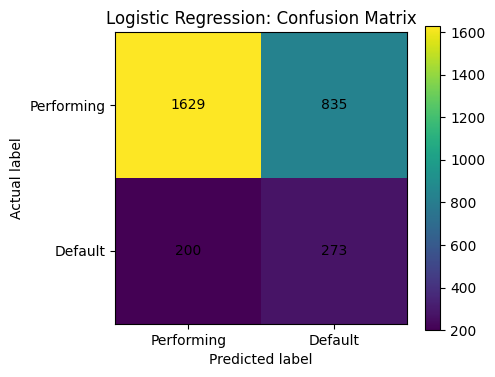


--------------------------------------------------------------------------------
XGBoost — Confusion Matrix (threshold = 0.5)
Rows = actual [0, 1]; columns = predicted [0, 1]
[[2448   16]
 [ 457   16]]

Classification report:
                precision    recall  f1-score   support

Performing (0)       0.84      0.99      0.91      2464
   Default (1)       0.50      0.03      0.06       473

      accuracy                           0.84      2937
     macro avg       0.67      0.51      0.49      2937
  weighted avg       0.79      0.84      0.78      2937



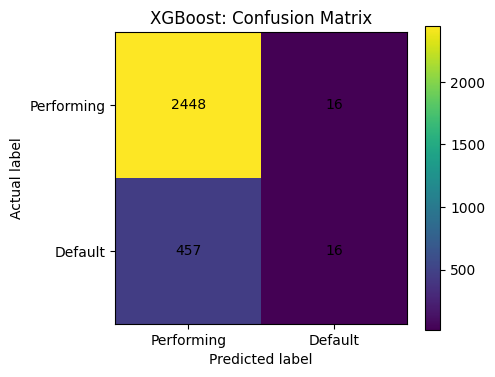

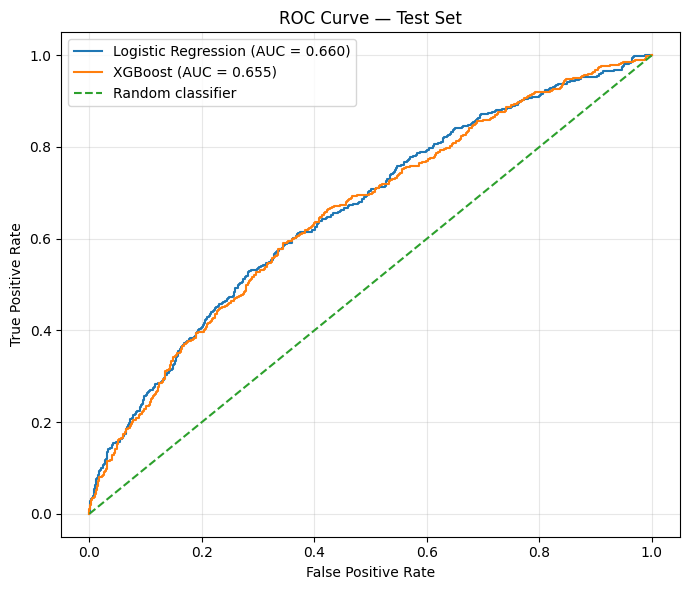

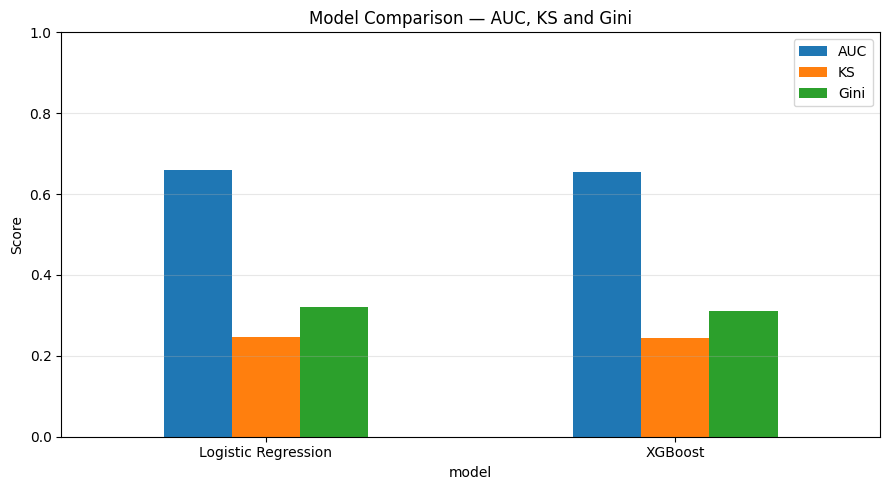


Calculating XGBoost permutation importance...
This may take a few minutes.


,feature,importance_mean,importance_std
0,annual_income,0.05474,0.00797
1,age,0.01983,0.00393
2,years_employed,0.01976,0.00636
3,early_total_emi_due,0.00738,0.00131
4,interest_rate_pct,0.00678,0.00322
5,loan_amount,0.00343,0.00065
6,origination_month,0.00327,0.00131
7,early_total_emi_paid,0.00325,0.00114
8,bureau_total_sanctioned,0.00295,0.00127
9,marital_status,0.00245,0.00048


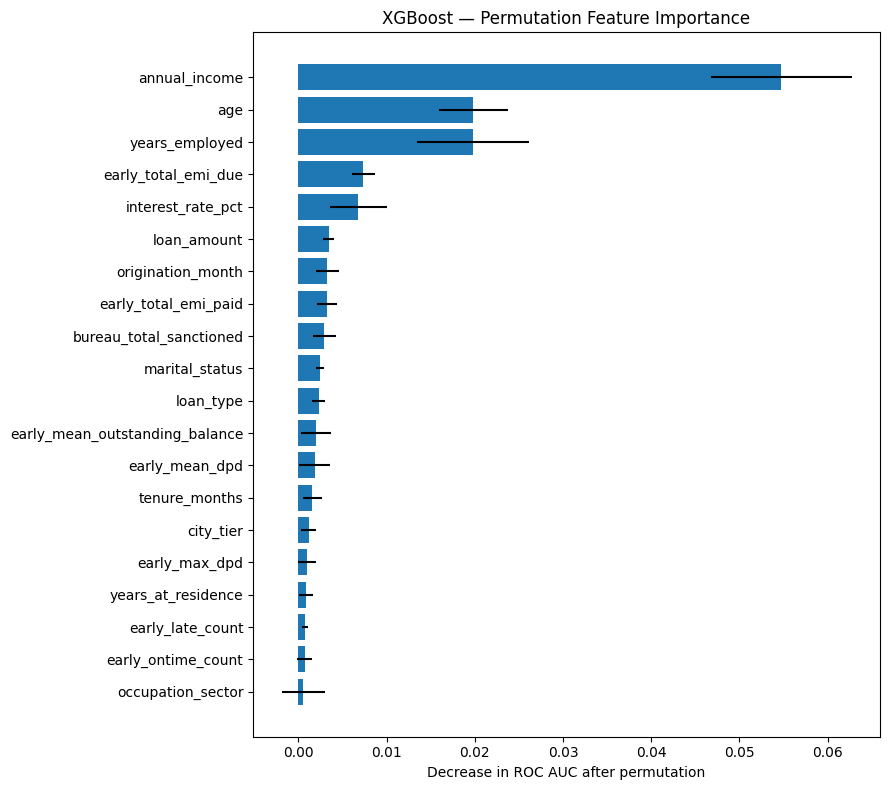


STEP 4 COMPLETE

Final metrics:


,model,AUC,KS,Gini,Brier,Accuracy_at_0.5,Precision_at_0.5,Recall_at_0.5,F1_at_0.5
0,Logistic Regression,0.660,0.2457,0.3199,0.2256,0.6476,0.2464,0.5772,0.3454
1,XGBoost,0.655,0.2453,0.3099,0.1291,0.8390,0.5000,0.0338,0.0634



Artifacts saved in: /content/credit_risk_step4_models

Files:
 - confusion_matrix_logistic.png
 - confusion_matrix_xgboost.png
 - logistic_regression_pipeline.joblib
 - model_comparison_auc_ks_gini.png
 - model_features.csv
 - model_limitations.md
 - model_metrics.csv
 - roc_curves.png
 - test_set_predictions.csv
 - train_test_split_manifest.csv
 - xgboost_feature_importance.png
 - xgboost_permutation_importance.csv
 - xgboost_pipeline.joblib

Next step: Step 5 — calibration, threshold analysis, final feature interpretation and monitoring documentation.


In [5]:

# ============================================================
# CREDIT RISK PORTFOLIO ANALYTICS
# STEP 4: MODEL PREPARATION + TRAINING + EVALUATION
#
# Models:
#   1. Logistic Regression
#   2. XGBoost
#
# Both use:
#   - Same features
#   - Same stratified train/test split
#   - Same preprocessing logic
#
# Outputs:
#   - Model metrics (AUC, KS, Gini, Brier)
#   - Confusion matrices
#   - ROC curve
#   - Feature importance using permutation importance
#   - Saved fitted pipelines
#
# IMPORTANT:
# Target timing and bureau reporting timing remain unresolved.
# ============================================================

import os
import sys
import subprocess
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    brier_score_loss,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.inspection import permutation_importance
from scipy.stats import ks_2samp

warnings.filterwarnings("ignore", category=FutureWarning)

# ------------------------------------------------------------
# 1. Install XGBoost if necessary
# ------------------------------------------------------------

try:
    import xgboost as xgb
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "xgboost"
    ])
    import xgboost as xgb

from xgboost import XGBClassifier

# ------------------------------------------------------------
# 2. Load the engineered dataset if needed
# ------------------------------------------------------------

if "model_df" not in globals():
    MODEL_PATH = (
        "/content/credit_risk_step3_features/model_df_engineered.csv"
    )

    if not os.path.exists(MODEL_PATH):
        raise FileNotFoundError(
            "Engineered dataset not found. Run Step 3 first."
        )

    model_df = pd.read_csv(MODEL_PATH)

# Work on a fresh copy.
model_data = model_df.copy()

OUTPUT_DIR = "/content/credit_risk_step4_models"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 80)
print("STEP 4: MODEL TRAINING")
print("=" * 80)
print("Input shape:", model_data.shape)

# ------------------------------------------------------------
# 3. Validate the target and account grain
# ------------------------------------------------------------

if "target_default" not in model_data.columns:
    raise KeyError("target_default is missing from model_df.")

if "account_id" not in model_data.columns:
    raise KeyError("account_id is missing from model_df.")

if model_data["account_id"].duplicated().any():
    raise ValueError(
        "Duplicate account_id rows detected. "
        "There must be exactly one row per loan."
    )

if model_data["target_default"].isna().any():
    raise ValueError(
        "Missing target_default values detected. "
        "Investigate before model training."
    )

if not set(model_data["target_default"].unique()).issubset({0, 1}):
    raise ValueError("target_default must contain only 0 and 1.")

y = model_data["target_default"].astype(int)

print("\nTarget distribution:")
display(
    y.value_counts()
    .sort_index()
    .rename_axis("target_default")
    .reset_index(name="count")
)

print("\nDefault rate:", round(y.mean() * 100, 2), "%")

# ------------------------------------------------------------
# 4. Create the feature set
#
# Exclusions:
# - target_default: label, never a feature
# - account_id/customer_id: identifiers
# - raw origination_date/customer_since: raw dates
# - customer_tenure_days_at_origination: invalid for 7,293
#   rows because customer_since occurs after origination
# - collection events: not included due to timing issues
# - current bureau status: not included because reporting
#   timing is not supplied
#
# The early repayment features remain included to satisfy
# the assignment's requested feature engineering. Their
# temporal relationship to the target is unverified.
# ------------------------------------------------------------

exclude_columns = [
    "target_default",
    "account_id",
    "customer_id",
    "origination_date",
    "customer_since",
    "customer_tenure_days_at_origination",
    "bureau_active_count",
    "bureau_closed_count",
    "bureau_written_off_count"
]

# Remove any excluded columns that are not present.
exclude_columns = [
    col for col in exclude_columns
    if col in model_data.columns
]

X = model_data.drop(columns=exclude_columns).copy()

# Prevent accidental inclusion of any other identifier-like
# columns if additional columns appear in the data.
identifier_columns = [
    col for col in X.columns
    if col.lower() in {
        "id", "account_id", "customer_id",
        "bureau_id", "collection_event_id"
    }
]

X = X.drop(columns=identifier_columns, errors="ignore")

# Standardize any remaining object values.
for col in X.select_dtypes(include=["object", "string"]).columns:
    X[col] = X[col].astype("string").str.strip()

# Convert datetime columns to explicit calendar components,
# or exclude them if no justified transformation is available.
datetime_columns = X.select_dtypes(
    include=["datetime", "datetimetz"]
).columns.tolist()

if datetime_columns:
    print(
        "\nDropping raw datetime columns from X:",
        datetime_columns
    )
    X = X.drop(columns=datetime_columns)

# Drop columns that contain no usable values.
all_missing_columns = [
    col for col in X.columns
    if X[col].isna().all()
]

if all_missing_columns:
    print("\nDropping all-missing features:", all_missing_columns)
    X = X.drop(columns=all_missing_columns)

# Remove constant features.
constant_columns = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

if constant_columns:
    print("\nDropping constant features:", constant_columns)
    X = X.drop(columns=constant_columns)

if X.empty:
    raise ValueError("No features remain after exclusions.")

print("\nFeature matrix shape:", X.shape)
print("Number of features before encoding:", X.shape[1])

print("\nFeature columns:")
print(X.columns.tolist())

# ------------------------------------------------------------
# 5. Add a missing-history indicator and handle bureau absence
#
# No eligible bureau records means absence of observed eligible
# history, not necessarily zero outstanding debt.
#
# Set numeric aggregates to 0 only when no eligible bureau
# records exist, and preserve a separate indicator.
# For accounts with bureau records but missing aggregate values,
# the imputer will learn the replacement from training data.
# ------------------------------------------------------------

if "bureau_account_count" in X.columns:
    X["has_eligible_bureau_history"] = (
        X["bureau_account_count"] > 0
    ).astype(int)

    no_bureau_mask = X["bureau_account_count"].eq(0)

    bureau_numeric_columns = [
        col for col in X.columns
        if col.startswith("bureau_")
        and col != "bureau_account_count"
    ]

    # Only set aggregate values to zero where no eligible records
    # were found at all; keep the history indicator to distinguish
    # this from observed zero balances or zero delinquency.
    X.loc[no_bureau_mask, bureau_numeric_columns] = (
        X.loc[no_bureau_mask, bureau_numeric_columns].fillna(0)
    )

print("\nEligible bureau history coverage:")
if "has_eligible_bureau_history" in X.columns:
    display(
        X["has_eligible_bureau_history"]
        .value_counts()
        .rename_axis("has_eligible_bureau_history")
        .reset_index(name="count")
    )

# ------------------------------------------------------------
# 6. Define numeric and categorical columns
# ------------------------------------------------------------

categorical_columns = X.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

numeric_columns = [
    col for col in X.columns
    if col not in categorical_columns
]

# Make numeric columns numeric where possible.
for col in numeric_columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

# If conversion creates an entirely missing numeric feature,
# remove it before building the pipeline.
all_missing_numeric = [
    col for col in numeric_columns
    if X[col].isna().all()
]

if all_missing_numeric:
    print(
        "\nRemoving numeric columns with no valid values:",
        all_missing_numeric
    )
    X = X.drop(columns=all_missing_numeric)
    numeric_columns = [
        col for col in numeric_columns
        if col not in all_missing_numeric
    ]

categorical_columns = [
    col for col in categorical_columns
    if col in X.columns
]

print("\nNumeric features:", len(numeric_columns))
print("Categorical features:", len(categorical_columns))

print("\nNumeric columns:")
print(numeric_columns)

print("\nCategorical columns:")
print(categorical_columns)

# ------------------------------------------------------------
# 7. Train/test split
#
# Keep the test set untouched until final evaluation.
# The same split is used for both algorithms.
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTrain rows:", len(X_train))
print("Test rows:", len(X_test))
print("Train default rate:", round(y_train.mean() * 100, 2), "%")
print("Test default rate:", round(y_test.mean() * 100, 2), "%")

# Save the split row indices for reproducibility.
split_manifest = pd.DataFrame({
    "row_index": X.index,
    "split": np.where(X.index.isin(X_test.index), "test", "train"),
    "target_default": y
})

split_manifest.to_csv(
    os.path.join(OUTPUT_DIR, "train_test_split_manifest.csv"),
    index=False
)

# ------------------------------------------------------------
# 8. Build preprocessing pipelines
#
# Numeric:
# - Median imputation
# - Standard scaling for Logistic Regression
#
# Categorical:
# - Most-frequent imputation
# - One-hot encoding
#
# Preprocessing is fitted only on the training data.
# ------------------------------------------------------------

try:
    one_hot_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    )
except TypeError:
    # Compatibility with older scikit-learn versions.
    one_hot_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=True
    )

numeric_preprocessing_logistic = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

numeric_preprocessing_xgb = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", one_hot_encoder)
])

preprocessor_logistic = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessing_logistic, numeric_columns),
        ("categorical", categorical_preprocessing, categorical_columns)
    ],
    remainder="drop"
)

preprocessor_xgb = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessing_xgb, numeric_columns),
        ("categorical", categorical_preprocessing, categorical_columns)
    ],
    remainder="drop"
)

# ------------------------------------------------------------
# 9. Define both models
# ------------------------------------------------------------

logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_logistic),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        solver="liblinear",
        random_state=42
    ))
])

xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_xgb),
    ("model", XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.04,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=2.0,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

# ------------------------------------------------------------
# 10. Train the models
# ------------------------------------------------------------

print("\nTraining Logistic Regression...")
logistic_pipeline.fit(X_train, y_train)

print("Training XGBoost...")
xgb_pipeline.fit(X_train, y_train)

print("\nBoth models trained.")

# ------------------------------------------------------------
# 11. Calculate evaluation metrics
# ------------------------------------------------------------

def calculate_ks(y_true, scores):
    """
    Two-sample KS statistic comparing predicted scores for
    actual positives and actual negatives.
    """
    y_array = np.asarray(y_true)
    scores_array = np.asarray(scores)

    positive_scores = scores_array[y_array == 1]
    negative_scores = scores_array[y_array == 0]

    if len(positive_scores) == 0 or len(negative_scores) == 0:
        return np.nan

    return float(
        ks_2samp(
            positive_scores,
            negative_scores
        ).statistic
    )


def evaluate_model(model_name, fitted_pipeline, X_eval, y_eval):
    probabilities = fitted_pipeline.predict_proba(X_eval)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    auc = roc_auc_score(y_eval, probabilities)
    ks_value = calculate_ks(y_eval, probabilities)
    gini = 2 * auc - 1
    brier = brier_score_loss(y_eval, probabilities)

    return {
        "model": model_name,
        "AUC": auc,
        "KS": ks_value,
        "Gini": gini,
        "Brier": brier,
        "Accuracy_at_0.5": accuracy_score(y_eval, predictions),
        "Precision_at_0.5": precision_score(
            y_eval, predictions, zero_division=0
        ),
        "Recall_at_0.5": recall_score(
            y_eval, predictions, zero_division=0
        ),
        "F1_at_0.5": f1_score(
            y_eval, predictions, zero_division=0
        )
    }


logistic_probabilities = logistic_pipeline.predict_proba(
    X_test
)[:, 1]

xgb_probabilities = xgb_pipeline.predict_proba(
    X_test
)[:, 1]

metrics = pd.DataFrame([
    evaluate_model(
        "Logistic Regression",
        logistic_pipeline,
        X_test,
        y_test
    ),
    evaluate_model(
        "XGBoost",
        xgb_pipeline,
        X_test,
        y_test
    )
])

print("\n" + "=" * 80)
print("TEST SET MODEL METRICS")
print("=" * 80)
display(metrics.round(4))

metrics.to_csv(
    os.path.join(OUTPUT_DIR, "model_metrics.csv"),
    index=False
)

# ------------------------------------------------------------
# 12. Confusion matrices and classification reports
# Threshold 0.5 is used here for a consistent initial comparison.
# It is not necessarily the optimal business threshold.
# ------------------------------------------------------------

for model_name, probabilities in [
    ("Logistic Regression", logistic_probabilities),
    ("XGBoost", xgb_probabilities)
]:
    predictions = (probabilities >= 0.5).astype(int)
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    print("\n" + "-" * 80)
    print(model_name, "— Confusion Matrix (threshold = 0.5)")
    print("Rows = actual [0, 1]; columns = predicted [0, 1]")
    print(cm)

    print("\nClassification report:")
    print(
        classification_report(
            y_test,
            predictions,
            labels=[0, 1],
            target_names=["Performing (0)", "Default (1)"],
            zero_division=0
        )
    )

    fig, ax = plt.subplots(figsize=(5, 4))
    image = ax.imshow(cm, interpolation="nearest")
    ax.set_title(f"{model_name}: Confusion Matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    ax.set_xticks([0, 1], labels=["Performing", "Default"])
    ax.set_yticks([0, 1], labels=["Performing", "Default"])

    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center", va="center"
            )

    fig.colorbar(image, ax=ax)
    fig.tight_layout()

    filename = (
        "confusion_matrix_logistic.png"
        if model_name == "Logistic Regression"
        else "confusion_matrix_xgboost.png"
    )

    fig.savefig(
        os.path.join(OUTPUT_DIR, filename),
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 13. ROC curve
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 6))

for model_name, probabilities in [
    ("Logistic Regression", logistic_probabilities),
    ("XGBoost", xgb_probabilities)
]:
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc_value = roc_auc_score(y_test, probabilities)

    ax.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_value:.3f})"
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve — Test Set")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()

fig.savefig(
    os.path.join(OUTPUT_DIR, "roc_curves.png"),
    dpi=160,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 14. AUC, KS, and Gini comparison chart
# ------------------------------------------------------------

plot_metrics = metrics.set_index("model")[["AUC", "KS", "Gini"]]

ax = plot_metrics.plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0
)

ax.set_title("Model Comparison — AUC, KS and Gini")
ax.set_ylabel("Score")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "model_comparison_auc_ks_gini.png"),
    dpi=160,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 15. Permutation feature importance
#
# Importance is measured as the reduction in test-set ROC AUC
# when a raw input feature is permuted.
#
# This can take a few minutes because predictions are repeated.
# The test set is used for interpretation here; use a separate
# validation set if you later select features or tune parameters.
# ------------------------------------------------------------

print("\nCalculating XGBoost permutation importance...")
print("This may take a few minutes.")

permutation_result = permutation_importance(
    xgb_pipeline,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

feature_importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": permutation_result.importances_mean,
    "importance_std": permutation_result.importances_std
}).sort_values(
    "importance_mean",
    ascending=False
).reset_index(drop=True)

display(feature_importance_df.head(20).round(5))

feature_importance_df.to_csv(
    os.path.join(OUTPUT_DIR, "xgboost_permutation_importance.csv"),
    index=False
)

top_features = feature_importance_df.head(20).sort_values(
    "importance_mean",
    ascending=True
)

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(
    top_features["feature"],
    top_features["importance_mean"],
    xerr=top_features["importance_std"]
)
ax.set_title("XGBoost — Permutation Feature Importance")
ax.set_xlabel("Decrease in ROC AUC after permutation")
fig.tight_layout()

fig.savefig(
    os.path.join(OUTPUT_DIR, "xgboost_feature_importance.png"),
    dpi=160,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 16. Save fitted pipelines and evaluation predictions
# ------------------------------------------------------------

joblib.dump(
    logistic_pipeline,
    os.path.join(OUTPUT_DIR, "logistic_regression_pipeline.joblib")
)

joblib.dump(
    xgb_pipeline,
    os.path.join(OUTPUT_DIR, "xgboost_pipeline.joblib")
)

predictions_df = pd.DataFrame({
    "row_index": X_test.index,
    "actual_target_default": y_test.to_numpy(),
    "logistic_probability": logistic_probabilities,
    "logistic_prediction_at_0.5": (
        logistic_probabilities >= 0.5
    ).astype(int),
    "xgboost_probability": xgb_probabilities,
    "xgboost_prediction_at_0.5": (
        xgb_probabilities >= 0.5
    ).astype(int)
})

predictions_df.to_csv(
    os.path.join(OUTPUT_DIR, "test_set_predictions.csv"),
    index=False
)

pd.Series(X.columns, name="feature").to_csv(
    os.path.join(OUTPUT_DIR, "model_features.csv"),
    index=False
)

# ------------------------------------------------------------
# 17. Write a preliminary limitations file
# ------------------------------------------------------------

limitations_text = """
CREDIT RISK MODEL — PRELIMINARY EVALUATION LIMITATIONS

Models:
- Logistic Regression baseline.
- XGBoost classifier.
- Both models use the same feature set and the same stratified
  train/test split.

Target:
- target_default was preserved as provided.
- The data dictionary does not define the target observation window,
  default event date, or exact target-generation rule.

Repayment features:
- Months 1-3 repayment aggregates were included because repayment
  feature engineering is required by the assignment.
- Their temporal relationship to target_default is not established.
- Therefore, these results must not be described as leakage-free.

Bureau features:
- Bureau records opened after loan origination were excluded from
  the origination-cutoff aggregate.
- Bureau reporting dates for outstanding balances and delinquency
  are unavailable, so reporting-time leakage cannot be ruled out.

Collections:
- Collections events were excluded because event dates include
  records before and after associated loan origination.

Preprocessing:
- Numeric imputation, scaling, and categorical encoding were fitted
  using training data through sklearn pipelines.
- The test set was used for initial model evaluation.
- The probability threshold of 0.5 is a reference threshold, not
  an optimized business decision threshold.

Interpretation:
- Performance metrics are preliminary and conditional on the
  undocumented synthetic target definition and timing assumptions.
- Feature importance indicates predictive association, not causality.
"""

with open(
    os.path.join(OUTPUT_DIR, "model_limitations.md"),
    "w",
    encoding="utf-8"
) as file:
    file.write(limitations_text.strip())

# ------------------------------------------------------------
# 18. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 4 COMPLETE")
print("=" * 80)

print("\nFinal metrics:")
display(metrics.round(4))

print("\nArtifacts saved in:", OUTPUT_DIR)
print("\nFiles:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", filename)

print(
    "\nNext step: Step 5 — calibration, threshold analysis, "
    "final feature interpretation and monitoring documentation."
)




In [6]:
# STEP 5A: VERIFY STEP 4 ARTIFACTS AND PREDICTION COLUMNS

import os
import pandas as pd

STEP4_DIR = "/content/credit_risk_step4_models"

required_files = [
    "test_set_predictions.csv",
    "model_metrics.csv",
    "xgboost_permutation_importance.csv",
]

print("=" * 75)
print("STEP 5A: ARTIFACT VERIFICATION")
print("=" * 75)

for filename in required_files:
    filepath = os.path.join(STEP4_DIR, filename)
    print(f"{filename}: {'FOUND' if os.path.exists(filepath) else 'MISSING'}")

if not os.path.isdir(STEP4_DIR):
    raise FileNotFoundError(
        f"Folder not found: {STEP4_DIR}. Run this cell in the Colab session "
        "where Step 4 was executed."
    )

predictions_path = os.path.join(STEP4_DIR, "test_set_predictions.csv")

if not os.path.exists(predictions_path):
    raise FileNotFoundError(
        "test_set_predictions.csv is missing. Please check whether the Step 4 "
        "artifacts are still available in this Colab session."
    )

predictions_df = pd.read_csv(predictions_path)

print("\nPrediction dataset shape:", predictions_df.shape)
print("\nExact column names:")
for column in predictions_df.columns:
    print("-", repr(column))

print("\nFirst five rows:")
display(predictions_df.head())

print("\nData types:")
display(predictions_df.dtypes.to_frame("data_type"))

print("\nVerification complete.")
print("Use the exact target and probability column names shown above in Step 5.")

STEP 5A: ARTIFACT VERIFICATION
test_set_predictions.csv: FOUND
model_metrics.csv: FOUND
xgboost_permutation_importance.csv: FOUND

Prediction dataset shape: (2937, 6)

Exact column names:
- 'row_index'
- 'actual_target_default'
- 'logistic_probability'
- 'logistic_prediction_at_0.5'
- 'xgboost_probability'
- 'xgboost_prediction_at_0.5'

First five rows:


,row_index,actual_target_default,logistic_probability,logistic_prediction_at_0.5,xgboost_probability,xgboost_prediction_at_0.5
0,8722,0,0.432662,0,0.145415,0
1,13561,0,0.527430,1,0.162243,0
2,6520,0,0.508821,1,0.175595,0
3,6225,0,0.392279,0,0.139817,0
4,512,1,0.342376,0,0.055533,0



Data types:


,data_type
row_index,int64
actual_target_default,int64
logistic_probability,float64
logistic_prediction_at_0.5,int64
xgboost_probability,float64
xgboost_prediction_at_0.5,int64



Verification complete.
Use the exact target and probability column names shown above in Step 5.


STEP 5: FINAL MODEL EVALUATION

Evaluation rows: 2,937
Observed default rate: 16.10%

2. THRESHOLD ANALYSIS

Threshold comparison:


,model,threshold,default_precision,default_recall,default_f1,specificity,accuracy,predicted_default_rate,true_positives,false_positives,false_negatives
0,Logistic Regression,0.05,0.1610,1.0000,0.2774,0.0000,0.1610,1.0000,473,2464,0
1,Logistic Regression,0.10,0.1612,1.0000,0.2777,0.0012,0.1621,0.9990,473,2461,0
2,Logistic Regression,0.15,0.1618,1.0000,0.2786,0.0057,0.1658,0.9952,473,2450,0
3,Logistic Regression,0.20,0.1644,0.9979,0.2823,0.0264,0.1828,0.9775,472,2399,1
4,Logistic Regression,0.25,0.1653,0.9683,0.2824,0.0613,0.2074,0.9435,458,2313,15
5,Logistic Regression,0.30,0.1733,0.9450,0.2928,0.1343,0.2649,0.8784,447,2133,26
6,Logistic Regression,0.35,0.1836,0.8922,0.3046,0.2386,0.3439,0.7824,422,1876,51
7,Logistic Regression,0.40,0.2001,0.8203,0.3217,0.3705,0.4430,0.6602,388,1551,85
8,Logistic Regression,0.45,0.2133,0.6871,0.3255,0.5134,0.5414,0.5189,325,1199,148
9,Logistic Regression,0.50,0.2464,0.5772,0.3454,0.6611,0.6476,0.3773,273,835,200


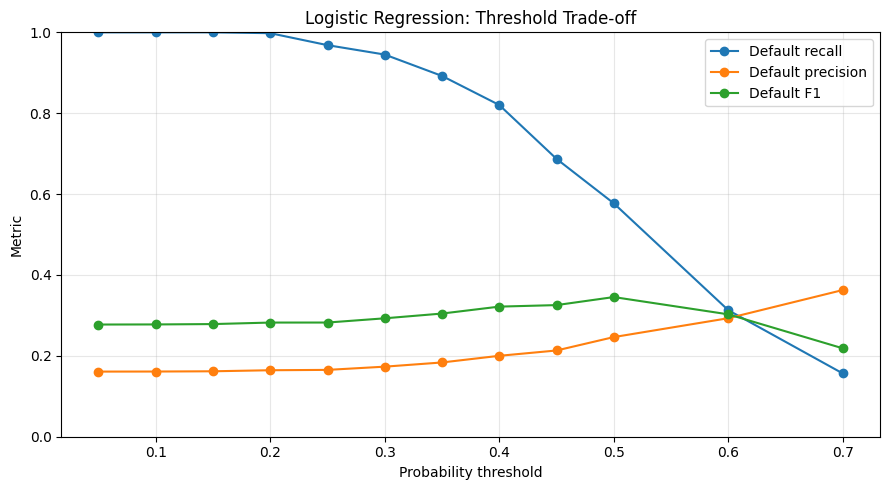

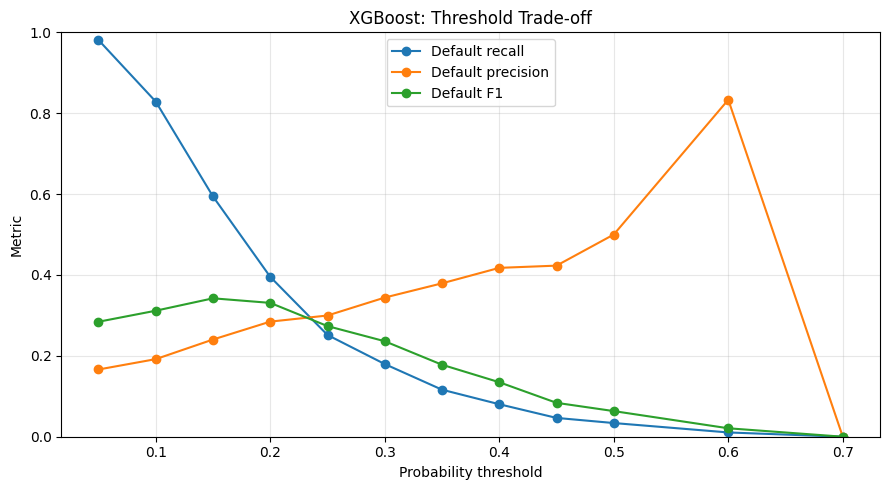


3. PROBABILITY CALIBRATION


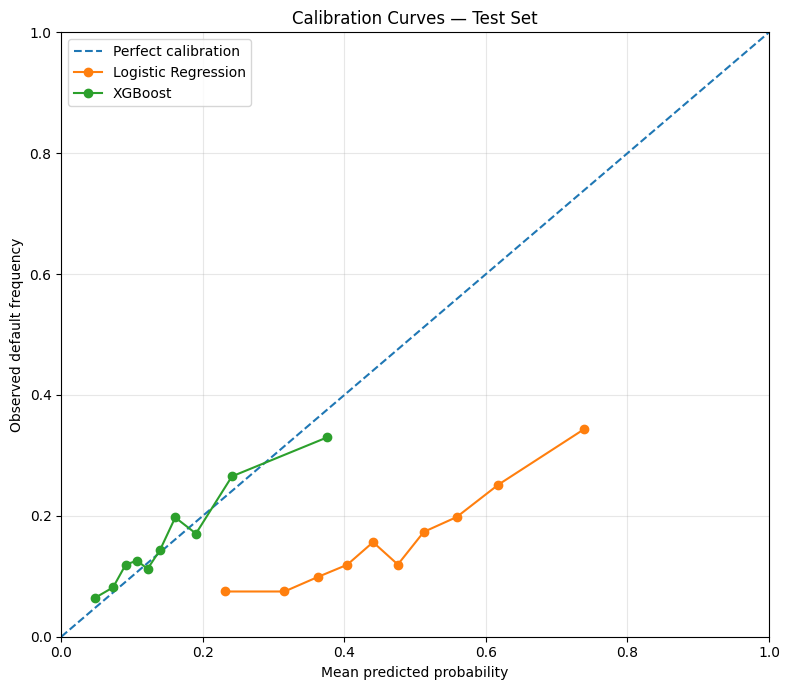


Calibration metrics:


,model,AUC,Gini,Brier_score,mean_predicted_probability,observed_default_rate
0,Logistic Regression,0.660,0.3199,0.2256,0.4657,0.161
1,XGBoost,0.655,0.3099,0.1291,0.1549,0.161



4. XGBOOST PERMUTATION FEATURE IMPORTANCE

Top 15 features:


,feature,importance_mean,importance_std
0,annual_income,0.05474,0.00797
1,age,0.01983,0.00393
2,years_employed,0.01976,0.00636
3,early_total_emi_due,0.00738,0.00131
4,interest_rate_pct,0.00678,0.00322
5,loan_amount,0.00343,0.00065
6,origination_month,0.00327,0.00131
7,early_total_emi_paid,0.00325,0.00114
8,bureau_total_sanctioned,0.00295,0.00127
9,marital_status,0.00245,0.00048


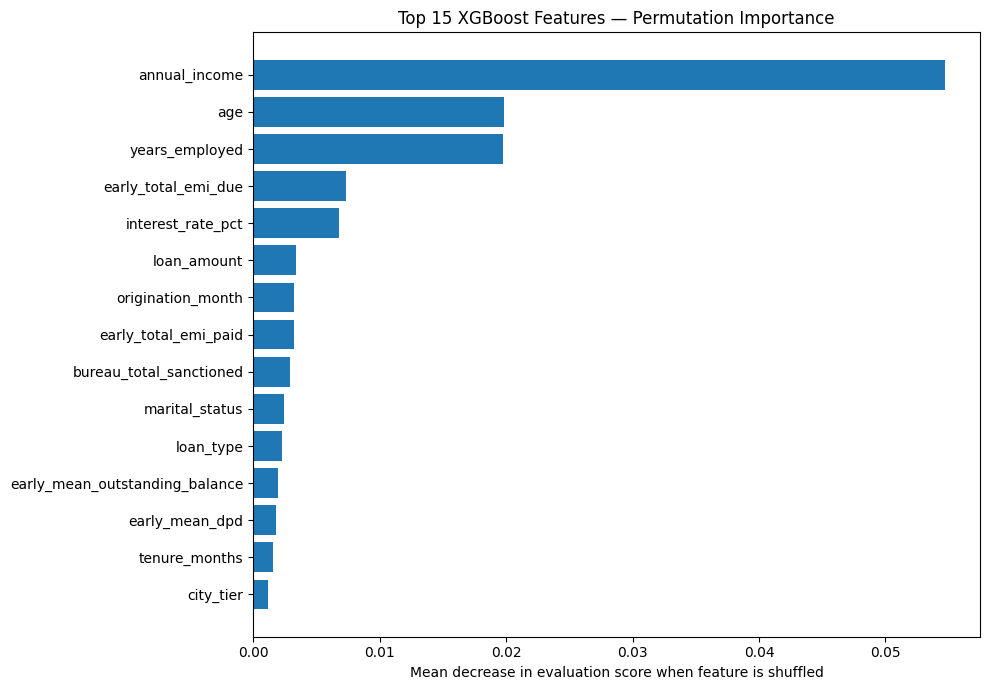


5. ORIGINAL STEP 4 MODEL METRICS


,model,AUC,KS,Gini,Brier,Accuracy_at_0.5,Precision_at_0.5,Recall_at_0.5,F1_at_0.5
0,Logistic Regression,0.660,0.2457,0.3199,0.2256,0.6476,0.2464,0.5772,0.3454
1,XGBoost,0.655,0.2453,0.3099,0.1291,0.8390,0.5000,0.0338,0.0634



Monitoring paragraph saved.
After deployment, monitor Population Stability Index (PSI) for the model-score
distribution and Characteristic Stability Index (CSI) for individual predictor
distributions, comparing each monitoring period with a documented training or
validation reference population. As practical screening guidelines, PSI below
0.10 is often considered limited change, 0.10–0.25 may indicate a shift requiring
investigation, and above 0.25 may indicate material change. These are heuristics,
not universal regulatory thresholds. Monitor missingness, category distributions,
out-of-range values, score distributions, and, when outcomes mature, AUC, KS,
calibration, and realized default rates. Generate monthly monitoring reports and
conduct a formal quarterly review, with earlier investigation when approved
limits are breached. Retraining should follow investigation of persistent drift
or performance deterioration, confirmation that target labels have matured, and
successful out-o

,model,AUC,Gini,Brier_score
0,Logistic Regression,0.660,0.3199,0.2256
1,XGBoost,0.655,0.3099,0.1291



All outputs saved in: /content/credit_risk_step5_evaluation

Files generated:
 - calibration_curves.png
 - calibration_metrics.csv
 - logistic_threshold_tradeoff.png
 - monitoring_plan.txt
 - step5_evaluation_report.txt
 - step5_model_summary.csv
 - threshold_analysis.csv
 - top_15_xgboost_permutation_importance.csv
 - top_15_xgboost_permutation_importance.png
 - xgboost_threshold_tradeoff.png


In [7]:

# ================================================================
# STEP 5: CALIBRATION, THRESHOLD ANALYSIS, FEATURE INTERPRETATION
#        AND PSI/CSI MONITORING DOCUMENTATION
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
)
from sklearn.calibration import calibration_curve
from IPython.display import display

print("=" * 80)
print("STEP 5: FINAL MODEL EVALUATION")
print("=" * 80)

# ------------------------------------------------
# 1. LOAD STEP 4 ARTIFACTS
# ------------------------------------------------

STEP4_DIR = "/content/credit_risk_step4_models"
STEP5_DIR = "/content/credit_risk_step5_evaluation"

os.makedirs(STEP5_DIR, exist_ok=True)

predictions_path = os.path.join(
    STEP4_DIR, "test_set_predictions.csv"
)
metrics_path = os.path.join(
    STEP4_DIR, "model_metrics.csv"
)
importance_path = os.path.join(
    STEP4_DIR, "xgboost_permutation_importance.csv"
)

if not os.path.exists(predictions_path):
    raise FileNotFoundError(
        f"Missing predictions file: {predictions_path}"
    )

predictions_df = pd.read_csv(predictions_path)

# Exact column names verified in Step 5A.
TARGET_COL = "actual_target_default"
LOGISTIC_PROB_COL = "logistic_probability"
XGBOOST_PROB_COL = "xgboost_probability"

required_columns = [
    TARGET_COL,
    LOGISTIC_PROB_COL,
    XGBOOST_PROB_COL,
]

missing_columns = [
    col for col in required_columns
    if col not in predictions_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

evaluation_df = predictions_df[required_columns].copy()
evaluation_df = evaluation_df.apply(
    pd.to_numeric, errors="coerce"
).dropna()

y_true = evaluation_df[TARGET_COL].astype(int).to_numpy()
logistic_prob = evaluation_df[LOGISTIC_PROB_COL].to_numpy()
xgboost_prob = evaluation_df[XGBOOST_PROB_COL].to_numpy()

if not set(np.unique(y_true)).issubset({0, 1}):
    raise ValueError("The target must contain only 0 and 1.")

for name, probabilities in [
    ("Logistic Regression", logistic_prob),
    ("XGBoost", xgboost_prob),
]:
    if np.any((probabilities < 0) | (probabilities > 1)):
        raise ValueError(
            f"{name} probability values must be between 0 and 1."
        )

print(f"\nEvaluation rows: {len(y_true):,}")
print(f"Observed default rate: {y_true.mean():.2%}")

# ------------------------------------------------
# 2. THRESHOLD ANALYSIS
# ------------------------------------------------

print("\n" + "=" * 80)
print("2. THRESHOLD ANALYSIS")
print("=" * 80)

thresholds = [
    0.05, 0.10, 0.15, 0.20, 0.25, 0.30,
    0.35, 0.40, 0.45, 0.50, 0.60, 0.70
]

threshold_rows = []

for model_name, probabilities in [
    ("Logistic Regression", logistic_prob),
    ("XGBoost", xgboost_prob),
]:
    for threshold in thresholds:
        y_pred = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        ).ravel()

        threshold_rows.append({
            "model": model_name,
            "threshold": threshold,
            "true_positives": tp,
            "false_positives": fp,
            "true_negatives": tn,
            "false_negatives": fn,
            "default_precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "default_recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "default_f1": f1_score(
                y_true, y_pred, zero_division=0
            ),
            "specificity": (
                tn / (tn + fp) if (tn + fp) > 0 else np.nan
            ),
            "accuracy": accuracy_score(y_true, y_pred),
            "predicted_default_rate": y_pred.mean(),
        })

threshold_df = pd.DataFrame(threshold_rows)

threshold_df.to_csv(
    os.path.join(STEP5_DIR, "threshold_analysis.csv"),
    index=False,
)

print("\nThreshold comparison:")
display(
    threshold_df[
        [
            "model", "threshold",
            "default_precision", "default_recall",
            "default_f1", "specificity", "accuracy",
            "predicted_default_rate",
            "true_positives", "false_positives",
            "false_negatives",
        ]
    ].round(4)
)

# Plot precision, recall and F1 at different thresholds.
for model_name in ["Logistic Regression", "XGBoost"]:
    model_data = threshold_df[
        threshold_df["model"] == model_name
    ]

    plt.figure(figsize=(9, 5))

    plt.plot(
        model_data["threshold"],
        model_data["default_recall"],
        marker="o",
        label="Default recall",
    )

    plt.plot(
        model_data["threshold"],
        model_data["default_precision"],
        marker="o",
        label="Default precision",
    )

    plt.plot(
        model_data["threshold"],
        model_data["default_f1"],
        marker="o",
        label="Default F1",
    )

    plt.xlabel("Probability threshold")
    plt.ylabel("Metric")
    plt.title(f"{model_name}: Threshold Trade-off")
    plt.ylim(0, 1)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    filename = (
        "logistic_threshold_tradeoff.png"
        if model_name == "Logistic Regression"
        else "xgboost_threshold_tradeoff.png"
    )

    plt.savefig(
        os.path.join(STEP5_DIR, filename),
        dpi=160,
        bbox_inches="tight",
    )
    plt.show()

# ------------------------------------------------
# 3. CALIBRATION ANALYSIS
# ------------------------------------------------

print("\n" + "=" * 80)
print("3. PROBABILITY CALIBRATION")
print("=" * 80)

calibration_rows = []

plt.figure(figsize=(8, 7))
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Perfect calibration",
)

for model_name, probabilities in [
    ("Logistic Regression", logistic_prob),
    ("XGBoost", xgboost_prob),
]:
    auc = roc_auc_score(y_true, probabilities)
    gini = 2 * auc - 1
    brier = brier_score_loss(y_true, probabilities)

    observed_fraction, mean_probability = calibration_curve(
        y_true,
        probabilities,
        n_bins=10,
        strategy="quantile",
    )

    plt.plot(
        mean_probability,
        observed_fraction,
        marker="o",
        label=model_name,
    )

    calibration_rows.append({
        "model": model_name,
        "AUC": auc,
        "Gini": gini,
        "Brier_score": brier,
        "mean_predicted_probability": probabilities.mean(),
        "observed_default_rate": y_true.mean(),
    })

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed default frequency")
plt.title("Calibration Curves — Test Set")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(STEP5_DIR, "calibration_curves.png"),
    dpi=160,
    bbox_inches="tight",
)
plt.show()

calibration_df = pd.DataFrame(calibration_rows)

calibration_df.to_csv(
    os.path.join(STEP5_DIR, "calibration_metrics.csv"),
    index=False,
)

print("\nCalibration metrics:")
display(calibration_df.round(4))

# A lower Brier score is better overall, but it does not by itself
# prove good calibration. Interpret it alongside the calibration plot.

# ------------------------------------------------
# 4. FEATURE INTERPRETATION
# ------------------------------------------------

print("\n" + "=" * 80)
print("4. XGBOOST PERMUTATION FEATURE IMPORTANCE")
print("=" * 80)

if os.path.exists(importance_path):
    importance_df = pd.read_csv(importance_path)

    if {"feature", "importance_mean"}.issubset(
        importance_df.columns
    ):
        importance_df = importance_df.sort_values(
            "importance_mean",
            ascending=False,
        ).reset_index(drop=True)

        top15_df = importance_df.head(15).copy()

        top15_df.to_csv(
            os.path.join(
                STEP5_DIR,
                "top_15_xgboost_permutation_importance.csv",
            ),
            index=False,
        )

        print("\nTop 15 features:")
        display(top15_df.round(5))

        plot_df = top15_df.sort_values(
            "importance_mean", ascending=True
        )

        plt.figure(figsize=(10, 7))
        plt.barh(
            plot_df["feature"],
            plot_df["importance_mean"],
        )
        plt.xlabel(
            "Mean decrease in evaluation score when feature is shuffled"
        )
        plt.title("Top 15 XGBoost Features — Permutation Importance")
        plt.tight_layout()

        plt.savefig(
            os.path.join(
                STEP5_DIR,
                "top_15_xgboost_permutation_importance.png",
            ),
            dpi=160,
            bbox_inches="tight",
        )
        plt.show()

    else:
        print(
            "The importance CSV does not contain the expected columns."
        )
else:
    print("Permutation importance CSV was not found.")

# ------------------------------------------------
# 5. DISPLAY STEP 4 MODEL METRICS
# ------------------------------------------------

print("\n" + "=" * 80)
print("5. ORIGINAL STEP 4 MODEL METRICS")
print("=" * 80)

if os.path.exists(metrics_path):
    step4_metrics_df = pd.read_csv(metrics_path)
    display(step4_metrics_df.round(4))
else:
    print("Step 4 metrics file was not found.")

# ------------------------------------------------
# 6. PSI/CSI MONITORING DOCUMENTATION
# ------------------------------------------------

monitoring_paragraph = """
After deployment, monitor Population Stability Index (PSI) for the model-score
distribution and Characteristic Stability Index (CSI) for individual predictor
distributions, comparing each monitoring period with a documented training or
validation reference population. As practical screening guidelines, PSI below
0.10 is often considered limited change, 0.10–0.25 may indicate a shift requiring
investigation, and above 0.25 may indicate material change. These are heuristics,
not universal regulatory thresholds. Monitor missingness, category distributions,
out-of-range values, score distributions, and, when outcomes mature, AUC, KS,
calibration, and realized default rates. Generate monthly monitoring reports and
conduct a formal quarterly review, with earlier investigation when approved
limits are breached. Retraining should follow investigation of persistent drift
or performance deterioration, confirmation that target labels have matured, and
successful out-of-time validation and governance approval. Because this dataset
does not define the target event window and lacks verified bureau reporting dates,
the current results remain exploratory until feature availability and the target
prediction horizon are confirmed.
""".strip()

with open(
    os.path.join(STEP5_DIR, "monitoring_plan.txt"),
    "w",
    encoding="utf-8",
) as file:
    file.write(monitoring_paragraph)

print("\nMonitoring paragraph saved.")
print(monitoring_paragraph)

# ------------------------------------------------
# 7. WRITE THE FINAL EVALUATION REPORT
# ------------------------------------------------

limitations = [
    "The target event definition and prediction horizon are not documented.",
    "Early repayment features from months 1–3 may occur after the target event.",
    "Bureau opening dates exist, but reporting/as-of dates are unavailable.",
    "Collections data was excluded because temporal alignment is unreliable.",
    "Customer profile snapshot timing has not been independently verified.",
    "The stratified random split is not out-of-time validation.",
    "The results are exploratory, not production-ready lending validation.",
]

report_lines = [
    "CREDIT RISK PORTFOLIO ANALYTICS — STEP 5",
    "=" * 60,
    "",
    f"Evaluation observations: {len(y_true):,}",
    f"Observed test default rate: {y_true.mean():.4%}",
    "",
    "CALIBRATION METRICS",
    "-" * 30,
    calibration_df.to_string(index=False),
    "",
    "LIMITATIONS",
    "-" * 30,
]

report_lines.extend([f"- {item}" for item in limitations])
report_lines.extend([
    "",
    "PSI/CSI MONITORING PLAN",
    "-" * 30,
    monitoring_paragraph,
])

report_path = os.path.join(
    STEP5_DIR, "step5_evaluation_report.txt"
)

with open(
    report_path, "w", encoding="utf-8"
) as file:
    file.write("\n".join(report_lines))

summary_df = calibration_df[
    ["model", "AUC", "Gini", "Brier_score"]
].copy()

summary_df.to_csv(
    os.path.join(STEP5_DIR, "step5_model_summary.csv"),
    index=False,
)

# ------------------------------------------------
# 8. FINAL OUTPUTS
# ------------------------------------------------

print("\n" + "=" * 80)
print("STEP 5 COMPLETE")
print("=" * 80)

print("\nModel summary:")
display(summary_df.round(4))

print(f"\nAll outputs saved in: {STEP5_DIR}")
print("\nFiles generated:")

for filename in sorted(os.listdir(STEP5_DIR)):
    print(" -", filename)



STEP 6: ORIGINATION-ONLY MODEL REBUILD

Loan accounts file: /content/loan_accounts.csv

Original loan table shape: (14685, 11)
Columns: ['account_id', 'customer_id', 'loan_type', 'loan_purpose', 'loan_amount', 'interest_rate_pct', 'tenure_months', 'origination_date', 'disbursal_channel', 'collateral_flag', 'target_default']


,account_id,customer_id,loan_type,loan_purpose,loan_amount,interest_rate_pct,tenure_months,origination_date,disbursal_channel,collateral_flag,target_default
0,ACC200001,CUST100000,Mortgage,Wedding,306310.51,6.06,360,2022-10-18,Branch,1,1
1,ACC200002,CUST100001,Auto Loan,Home Improvement,33921.61,5.52,60,2022-12-19,Online,1,0
2,ACC200003,CUST100002,Personal Loan,Business Expansion,4469.93,10.98,48,2023-11-08,Mobile App,0,0
3,ACC200004,CUST100003,Personal Loan,Medical,26274.80,7.43,48,2020-04-06,Partner/DSA,0,0
4,ACC200005,CUST100003,Personal Loan,Vehicle Purchase,16356.86,10.63,36,2023-04-15,Online,0,0



Rows after basic validation: 14685

Target distribution:


,count
target_default,
0,12321
1,2364



Default rate: 16.10%

Feature matrix shape: (14685, 9)

Included features:
['loan_type', 'loan_purpose', 'loan_amount', 'interest_rate_pct', 'tenure_months', 'disbursal_channel', 'collateral_flag', 'origination_year', 'origination_month']

Excluded feature groups:
- account_id
- customer_id
- target_default
- customer profile fields with unverified snapshot timing
- bureau fields without verified reporting/as-of dates
- repayment aggregates from months 1-3
- collections events

Chronological holdout cutoff: 2022-10-18
Training date range: 2018-01-01 to 2022-10-17
Test date range: 2022-10-18 to 2023-12-30

Train rows: 11723
Test rows: 2962
Train default rate: 16.31%
Test default rate: 15.26%

Numeric features: ['loan_amount', 'interest_rate_pct', 'tenure_months', 'collateral_flag', 'origination_year', 'origination_month']

Categorical features: ['loan_type', 'loan_purpose', 'disbursal_channel']

Tree model used: XGBoost

Training Logistic Regression...
Training tree model...

Both mode

,model,AUC,KS,Gini,Brier,Accuracy_at_0.5,Precision_at_0.5,Recall_at_0.5,F1_at_0.5,TP,FP,TN,FN
0,Logistic Regression,0.5406,0.0761,0.0812,0.2537,0.5547,0.1632,0.4646,0.2415,210,1077,1433,242
1,XGBoost,0.5371,0.0684,0.0741,0.1307,0.8471,0.4545,0.0111,0.0216,5,6,2504,447



----------------------------------------------------------------------
Logistic Regression
----------------------------------------------------------------------

Confusion matrix:
[[1433 1077]
 [ 242  210]]

Classification report:
                precision    recall  f1-score   support

Performing (0)       0.86      0.57      0.68      2510
   Default (1)       0.16      0.46      0.24       452

      accuracy                           0.55      2962
     macro avg       0.51      0.52      0.46      2962
  weighted avg       0.75      0.55      0.62      2962


----------------------------------------------------------------------
XGBoost
----------------------------------------------------------------------

Confusion matrix:
[[2504    6]
 [ 447    5]]

Classification report:
                precision    recall  f1-score   support

Performing (0)       0.85      1.00      0.92      2510
   Default (1)       0.45      0.01      0.02       452

      accuracy                       

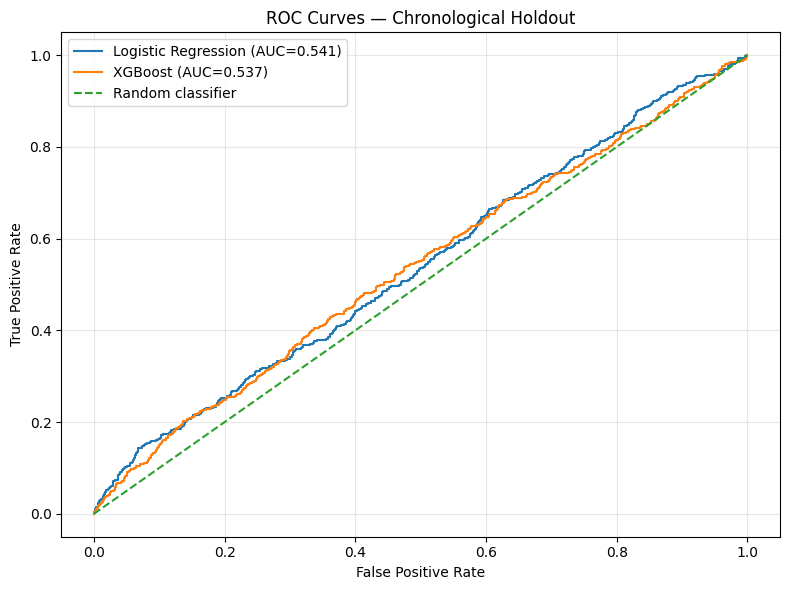


Calculating permutation importance for the tree model...
This may take a few minutes.

Origination-only feature importance:


,feature,importance_mean,importance_std
0,loan_amount,0.01419,0.00430
1,interest_rate_pct,0.00973,0.00153
2,origination_month,0.00837,0.01029
3,tenure_months,0.00633,0.00433
4,loan_purpose,0.00196,0.00327
5,origination_year,0.00000,0.00000
6,collateral_flag,-0.00175,0.00044
7,disbursal_channel,-0.00283,0.00747
8,loan_type,-0.00438,0.00164


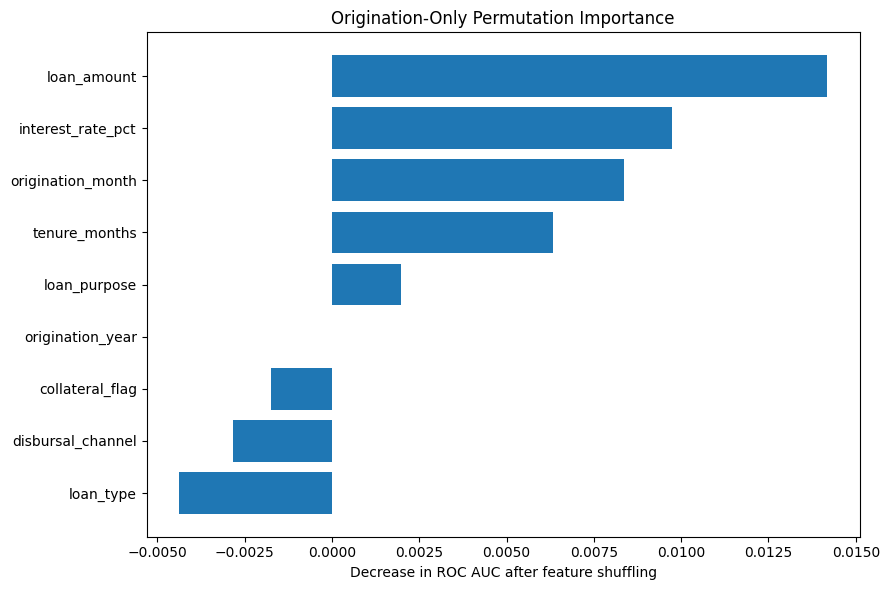


STEP 6 COMPLETE

Final chronological metrics:


,model,AUC,KS,Gini,Brier,Accuracy_at_0.5,Precision_at_0.5,Recall_at_0.5,F1_at_0.5,TP,FP,TN,FN
0,Logistic Regression,0.5406,0.0761,0.0812,0.2537,0.5547,0.1632,0.4646,0.2415,210,1077,1433,242
1,XGBoost,0.5371,0.0684,0.0741,0.1307,0.8471,0.4545,0.0111,0.0216,5,6,2504,447



Output directory: /content/credit_risk_step6_origination_only

Saved files:
 - chronological_model_metrics.csv
 - chronological_roc_curves.png
 - chronological_split_manifest.csv
 - chronological_test_predictions.csv
 - model_metadata.json
 - origination_feature_audit.csv
 - origination_feature_importance.png
 - origination_feature_list.csv
 - origination_logistic_pipeline.joblib
 - origination_model_limitations.txt
 - origination_permutation_importance.csv
 - origination_tree_pipeline.joblib


In [8]:

# ================================================================
# STEP 6: STRICT ORIGINATION-ONLY CREDIT RISK MODEL
# Logistic Regression + XGBoost + Chronological Holdout
# ================================================================

import os
import glob
import warnings
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    brier_score_loss,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

print("=" * 85)
print("STEP 6: ORIGINATION-ONLY MODEL REBUILD")
print("=" * 85)

# ------------------------------------------------
# 1. PATHS
# ------------------------------------------------

OUTPUT_DIR = "/content/credit_risk_step6_origination_only"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Find the source CSVs in common Colab locations.
def locate_csv(filename):
    candidates = [
        f"/content/{filename}",
        f"/content/drive/MyDrive/{filename}",
        filename,
    ]

    for path in candidates:
        if os.path.isfile(path):
            return path

    matches = glob.glob(f"/content/**/{filename}", recursive=True)
    if matches:
        return matches[0]

    raise FileNotFoundError(
        f"Could not find {filename}. Upload the original dataset CSVs "
        "to Colab or place them in /content."
    )

loan_path = locate_csv("loan_accounts.csv")
print("\nLoan accounts file:", loan_path)

# ------------------------------------------------
# 2. LOAD ORIGINAL LOAN TABLE
# ------------------------------------------------

loans = pd.read_csv(loan_path)

print("\nOriginal loan table shape:", loans.shape)
print("Columns:", loans.columns.tolist())
display(loans.head())

required_columns = [
    "account_id",
    "origination_date",
    "target_default",
]

missing_required = [
    col for col in required_columns if col not in loans.columns
]

if missing_required:
    raise ValueError(
        f"Missing required columns in loan_accounts.csv: {missing_required}"
    )

loans["origination_date"] = pd.to_datetime(
    loans["origination_date"], errors="coerce"
)

loans["target_default"] = pd.to_numeric(
    loans["target_default"], errors="coerce"
)

loans = loans.dropna(
    subset=["account_id", "origination_date", "target_default"]
).copy()

loans = loans[
    loans["target_default"].isin([0, 1])
].copy()

loans["target_default"] = loans["target_default"].astype(int)

if loans["account_id"].duplicated().any():
    raise ValueError(
        "account_id is not unique in loan_accounts.csv. "
        "Resolve duplicate accounts before modeling."
    )

if loans["target_default"].nunique() != 2:
    raise ValueError(
        "The target must contain both classes 0 and 1."
    )

print("\nRows after basic validation:", len(loans))
print("\nTarget distribution:")
display(loans["target_default"].value_counts().sort_index().to_frame("count"))

print(
    f"\nDefault rate: {loans['target_default'].mean():.2%}"
)

# ------------------------------------------------
# 3. BUILD STRICT ORIGINATION-ONLY FEATURES
# ------------------------------------------------

# These fields are retained only when they are part of the loan record
# and are intended to be known as part of origination.
# No repayment, bureau, collection, customer snapshot, target, or ID
# fields are included as predictors.

permitted_loan_fields = [
    "loan_type",
    "loan_purpose",
    "loan_amount",
    "interest_rate_pct",
    "tenure_months",
    "disbursal_channel",
    "collateral_flag",
]

feature_df = pd.DataFrame(index=loans.index)

for col in permitted_loan_fields:
    if col in loans.columns:
        feature_df[col] = loans[col]

# Origination calendar features are derived directly from origination date.
feature_df["origination_year"] = loans["origination_date"].dt.year
feature_df["origination_month"] = loans["origination_date"].dt.month

y = loans["target_default"].copy()

# Explicit exclusions for auditability.
excluded_predictors = [
    "account_id",
    "customer_id",
    "target_default",
    "customer profile fields with unverified snapshot timing",
    "bureau fields without verified reporting/as-of dates",
    "repayment aggregates from months 1-3",
    "collections events",
]

# Remove predictors that are unavailable or constant.
all_missing_features = [
    col for col in feature_df.columns if feature_df[col].isna().all()
]

if all_missing_features:
    feature_df = feature_df.drop(columns=all_missing_features)

constant_features = [
    col for col in feature_df.columns
    if feature_df[col].nunique(dropna=True) <= 1
]

if constant_features:
    feature_df = feature_df.drop(columns=constant_features)

if feature_df.shape[1] == 0:
    raise ValueError("No usable origination features remain.")

print("\nFeature matrix shape:", feature_df.shape)
print("\nIncluded features:")
print(feature_df.columns.tolist())

print("\nExcluded feature groups:")
for item in excluded_predictors:
    print("-", item)

# Save the feature list and a basic audit.
feature_audit = pd.DataFrame({
    "feature": feature_df.columns,
    "dtype": [str(feature_df[c].dtype) for c in feature_df.columns],
    "missing_count": [int(feature_df[c].isna().sum()) for c in feature_df.columns],
    "missing_percentage": [
        float(feature_df[c].isna().mean() * 100) for c in feature_df.columns
    ],
})

feature_audit.to_csv(
    os.path.join(OUTPUT_DIR, "origination_feature_audit.csv"),
    index=False,
)

feature_audit.to_csv(
    os.path.join(OUTPUT_DIR, "origination_feature_list.csv"),
    index=False,
)

# ------------------------------------------------
# 4. CHRONOLOGICAL TRAIN / TEST SPLIT
# ------------------------------------------------

# Use the latest 20% of distinct origination dates as the holdout period.
# All accounts from the cutoff date are assigned to the test set.
unique_dates = np.array(
    sorted(loans["origination_date"].dropna().unique())
)

if len(unique_dates) < 5:
    raise ValueError(
        "Too few distinct origination dates for a chronological holdout."
    )

cutoff_position = int(np.floor(len(unique_dates) * 0.80))
cutoff_position = min(max(cutoff_position, 1), len(unique_dates) - 1)
cutoff_date = pd.Timestamp(unique_dates[cutoff_position])

test_mask = loans["origination_date"] >= cutoff_date
train_mask = loans["origination_date"] < cutoff_date

X_train = feature_df.loc[train_mask].copy()
X_test = feature_df.loc[test_mask].copy()
y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

if len(X_train) == 0 or len(X_test) == 0:
    raise ValueError("Chronological split created an empty partition.")

if y_train.nunique() != 2 or y_test.nunique() != 2:
    raise ValueError(
        "The chronological split does not contain both target classes "
        "in train and test. Do not silently replace it with a random split. "
        "Inspect the target distribution by origination date and choose a "
        "defensible alternative validation design."
    )

print("\nChronological holdout cutoff:", cutoff_date.date())
print("Training date range:",
      loans.loc[train_mask, "origination_date"].min().date(),
      "to",
      loans.loc[train_mask, "origination_date"].max().date())
print("Test date range:",
      loans.loc[test_mask, "origination_date"].min().date(),
      "to",
      loans.loc[test_mask, "origination_date"].max().date())

print("\nTrain rows:", len(X_train))
print("Test rows:", len(X_test))
print(f"Train default rate: {y_train.mean():.2%}")
print(f"Test default rate: {y_test.mean():.2%}")

# Save account split membership for reproducibility.
split_manifest = loans[
    ["account_id", "origination_date", "target_default"]
].copy()

split_manifest["split"] = np.where(
    test_mask, "test_chronological", "train"
)

split_manifest.to_csv(
    os.path.join(OUTPUT_DIR, "chronological_split_manifest.csv"),
    index=False,
)

# ------------------------------------------------
# 5. PREPROCESSING
# ------------------------------------------------

numeric_features = feature_df.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = [
    col for col in feature_df.columns
    if col not in numeric_features
]

print("\nNumeric features:", numeric_features)
print("\nCategorical features:", categorical_features)

numeric_lr_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

numeric_tree_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

lr_transformers = [
    ("numeric", numeric_lr_pipeline, numeric_features),
]

tree_transformers = [
    ("numeric", numeric_tree_pipeline, numeric_features),
]

if categorical_features:
    lr_transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )
    tree_transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

lr_preprocessor = ColumnTransformer(
    transformers=lr_transformers,
    remainder="drop",
)

tree_preprocessor = ColumnTransformer(
    transformers=tree_transformers,
    remainder="drop",
)

# ------------------------------------------------
# 6. DEFINE BOTH MODELS
# ------------------------------------------------

logistic_model = Pipeline(steps=[
    ("preprocessor", lr_preprocessor),
    ("model", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        solver="liblinear",
        random_state=42,
    )),
])

# Prefer XGBoost when installed. Otherwise use a documented sklearn
# gradient-boosting fallback and record which model was used.
try:
    from xgboost import XGBClassifier

    model_type = "XGBoost"

    xgboost_estimator = XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.04,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=2,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1,
    )

except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier

    model_type = "HistGradientBoosting fallback (XGBoost unavailable)"

    # One-hot encoding is sparse by default. Use a dense representation
    # for this fallback model.
    from sklearn.preprocessing import FunctionTransformer

    tree_preprocessor = ColumnTransformer(
        transformers=tree_transformers,
        remainder="drop",
        sparse_threshold=0,
    )

    xgboost_estimator = HistGradientBoostingClassifier(
        max_iter=250,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42,
    )

tree_model = Pipeline(steps=[
    ("preprocessor", tree_preprocessor),
    ("model", xgboost_estimator),
])

print("\nTree model used:", model_type)

# ------------------------------------------------
# 7. TRAIN MODELS
# ------------------------------------------------

print("\nTraining Logistic Regression...")
logistic_model.fit(X_train, y_train)

print("Training tree model...")
tree_model.fit(X_train, y_train)

print("\nBoth models trained.")

# ------------------------------------------------
# 8. METRICS AND KS
# ------------------------------------------------

def calculate_ks(y_actual, probabilities):
    """
    Calculate the maximum absolute difference between empirical CDFs
    of scores for positive and negative cases.
    """
    y_array = np.asarray(y_actual)
    p_array = np.asarray(probabilities)

    positive_scores = np.sort(p_array[y_array == 1])
    negative_scores = np.sort(p_array[y_array == 0])

    if len(positive_scores) == 0 or len(negative_scores) == 0:
        return np.nan

    all_scores = np.sort(np.unique(p_array))
    positive_cdf = np.searchsorted(
        positive_scores, all_scores, side="right"
    ) / len(positive_scores)

    negative_cdf = np.searchsorted(
        negative_scores, all_scores, side="right"
    ) / len(negative_scores)

    return float(np.max(np.abs(positive_cdf - negative_cdf)))


def evaluate_model(model_name, y_actual, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)

    auc = roc_auc_score(y_actual, probabilities)
    ks = calculate_ks(y_actual, probabilities)

    tn, fp, fn, tp = confusion_matrix(
        y_actual, predictions, labels=[0, 1]
    ).ravel()

    return {
        "model": model_name,
        "AUC": auc,
        "KS": ks,
        "Gini": 2 * auc - 1,
        "Brier": brier_score_loss(y_actual, probabilities),
        "Accuracy_at_0.5": accuracy_score(y_actual, predictions),
        "Precision_at_0.5": precision_score(
            y_actual, predictions, zero_division=0
        ),
        "Recall_at_0.5": recall_score(
            y_actual, predictions, zero_division=0
        ),
        "F1_at_0.5": f1_score(
            y_actual, predictions, zero_division=0
        ),
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
    }


logistic_prob = logistic_model.predict_proba(X_test)[:, 1]
tree_prob = tree_model.predict_proba(X_test)[:, 1]

results = [
    evaluate_model(
        "Logistic Regression", y_test, logistic_prob
    ),
    evaluate_model(
        model_type, y_test, tree_prob
    ),
]

metrics_df = pd.DataFrame(results)

print("\n" + "=" * 85)
print("CHRONOLOGICAL TEST METRICS")
print("=" * 85)
display(metrics_df.round(4))

metrics_df.to_csv(
    os.path.join(OUTPUT_DIR, "chronological_model_metrics.csv"),
    index=False,
)

# ------------------------------------------------
# 9. CLASSIFICATION REPORTS AND CONFUSION MATRICES
# ------------------------------------------------

for model_name, probabilities in [
    ("Logistic Regression", logistic_prob),
    (model_type, tree_prob),
]:
    predictions = (probabilities >= 0.5).astype(int)

    print("\n" + "-" * 70)
    print(model_name)
    print("-" * 70)

    print("\nConfusion matrix:")
    print(confusion_matrix(y_test, predictions, labels=[0, 1]))

    print("\nClassification report:")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["Performing (0)", "Default (1)"],
        zero_division=0,
    ))

# ------------------------------------------------
# 10. ROC CURVES
# ------------------------------------------------

plt.figure(figsize=(8, 6))

for model_name, probabilities in [
    ("Logistic Regression", logistic_prob),
    (model_type, tree_prob),
]:
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr, tpr,
        label=f"{model_name} (AUC={auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Chronological Holdout")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "chronological_roc_curves.png"),
    dpi=160,
    bbox_inches="tight",
)
plt.show()

# ------------------------------------------------
# 11. PERMUTATION IMPORTANCE
# ------------------------------------------------

print("\nCalculating permutation importance for the tree model...")
print("This may take a few minutes.")

importance_result = permutation_importance(
    tree_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": importance_result.importances_mean,
    "importance_std": importance_result.importances_std,
}).sort_values(
    "importance_mean", ascending=False
).reset_index(drop=True)

importance_df.to_csv(
    os.path.join(OUTPUT_DIR, "origination_permutation_importance.csv"),
    index=False,
)

print("\nOrigination-only feature importance:")
display(importance_df.round(5))

plot_importance = importance_df.sort_values(
    "importance_mean", ascending=True
)

plt.figure(figsize=(9, 6))
plt.barh(
    plot_importance["feature"],
    plot_importance["importance_mean"],
)
plt.xlabel("Decrease in ROC AUC after feature shuffling")
plt.title("Origination-Only Permutation Importance")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "origination_feature_importance.png"),
    dpi=160,
    bbox_inches="tight",
)
plt.show()

# ------------------------------------------------
# 12. SAVE TEST PREDICTIONS
# ------------------------------------------------

test_predictions = loans.loc[
    test_mask,
    ["account_id", "origination_date", "target_default"]
].copy()

test_predictions = test_predictions.rename(
    columns={"target_default": "actual_target_default"}
)

test_predictions["logistic_probability"] = logistic_prob
test_predictions["logistic_prediction_at_0.5"] = (
    logistic_prob >= 0.5
).astype(int)

test_predictions["tree_probability"] = tree_prob
test_predictions["tree_prediction_at_0.5"] = (
    tree_prob >= 0.5
).astype(int)

test_predictions.to_csv(
    os.path.join(OUTPUT_DIR, "chronological_test_predictions.csv"),
    index=False,
)

# ------------------------------------------------
# 13. SAVE MODELS
# ------------------------------------------------

import joblib

joblib.dump(
    logistic_model,
    os.path.join(OUTPUT_DIR, "origination_logistic_pipeline.joblib"),
)

joblib.dump(
    tree_model,
    os.path.join(OUTPUT_DIR, "origination_tree_pipeline.joblib"),
)

# ------------------------------------------------
# 14. WRITE LIMITATIONS AND MODEL CARD
# ------------------------------------------------

limitations_text = f"""
CREDIT RISK MODEL — ORIGINATION-ONLY VERSION

Prediction point:
Loan origination.

Included predictors:
{", ".join(feature_df.columns.tolist())}

Excluded:
- Repayment history because it occurs after loan origination.
- Bureau balances and delinquency values because verified reporting/as-of dates
  are unavailable.
- Customer snapshot features because their availability at origination is not
  independently established.
- Collections events because event timing is unreliable.
- Account/customer identifiers and the target itself.

Validation:
A chronological holdout based on origination date was used. The latest 20%
of distinct origination dates form the test period. All rows on a given
origination date are assigned to the same partition.

Important limitations:
1. The target definition and default event window are not documented.
2. A chronological split does not prove the target event occurs after
   origination or that labels are observed on a consistent horizon.
3. The included loan fields are treated as origination fields based on their
   role in the loan record; confirm this against the source-system data
   dictionary before production use.
4. Bureau and repayment aggregates have intentionally not been included.
   They can only be added after establishing point-in-time availability.
5. This model is exploratory and not validated for real lending decisions.

Tree model implementation:
{model_type}
"""

with open(
    os.path.join(OUTPUT_DIR, "origination_model_limitations.txt"),
    "w",
    encoding="utf-8",
) as f:
    f.write(limitations_text)

# Save metadata.
metadata = {
    "prediction_point": "loan_origination",
    "target": "target_default",
    "tree_model_used": model_type,
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "train_default_rate": float(y_train.mean()),
    "test_default_rate": float(y_test.mean()),
    "test_start_date": str(
        loans.loc[test_mask, "origination_date"].min().date()
    ),
    "test_end_date": str(
        loans.loc[test_mask, "origination_date"].max().date()
    ),
    "feature_columns": feature_df.columns.tolist(),
    "bureau_features_included": False,
    "repayment_features_included": False,
    "target_horizon_verified": False,
}

with open(
    os.path.join(OUTPUT_DIR, "model_metadata.json"),
    "w",
    encoding="utf-8",
) as f:
    json.dump(metadata, f, indent=2)

# ------------------------------------------------
# 15. FINAL SUMMARY
# ------------------------------------------------

print("\n" + "=" * 85)
print("STEP 6 COMPLETE")
print("=" * 85)

print("\nFinal chronological metrics:")
display(metrics_df.round(4))

print("\nOutput directory:", OUTPUT_DIR)
print("\nSaved files:")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", filename)



In [9]:
import os
import shutil
import zipfile

# Source folder containing Step 4 model artifacts
SOURCE_DIR = "/content/credit_risk_step4_models"

# Output folder for dashboard and portfolio use
OUTPUT_DIR = "/content/credit_risk_dashboard_package"
ZIP_PATH = "/content/credit_risk_dashboard_package.zip"

if not os.path.isdir(SOURCE_DIR):
    raise FileNotFoundError(
        f"Step 4 folder not found: {SOURCE_DIR}. "
        "Check the folder exists in your Colab runtime."
    )

# Start with a clean output directory
if os.path.exists(OUTPUT_DIR):
    shutil.rmtree(OUTPUT_DIR)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Essential files for the dashboard and portfolio
KEEP_EXACT = {
    "model_metrics.csv",
    "test_set_predictions.csv",
    "top_15_xgboost_permutation_importance.csv",
    "model_comparison.csv",
    "split_manifest.csv",
}

# Keep model pipelines and useful model metadata
KEEP_KEYWORDS = (
    "logistic",
    "xgboost",
    "pipeline",
    "feature_importance",
    "permutation_importance",
    "confusion",
    "roc",
    "model_metadata",
    "model_limitations",
)

# Copy matching files while preserving subfolders
copied_files = []

for root, _, files in os.walk(SOURCE_DIR):
    for filename in files:
        lower_name = filename.lower()

        keep = (
            filename in KEEP_EXACT
            or lower_name.endswith((".joblib", ".pkl"))
            or any(keyword in lower_name for keyword in KEEP_KEYWORDS)
        )

        if not keep:
            continue

        source_path = os.path.join(root, filename)
        relative_path = os.path.relpath(source_path, SOURCE_DIR)
        destination_path = os.path.join(OUTPUT_DIR, relative_path)

        os.makedirs(os.path.dirname(destination_path), exist_ok=True)
        shutil.copy2(source_path, destination_path)
        copied_files.append(relative_path)

# Create ZIP archive
if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as archive:
    for root, _, files in os.walk(OUTPUT_DIR):
        for filename in files:
            full_path = os.path.join(root, filename)
            archive.write(
                full_path,
                arcname=os.path.relpath(full_path, OUTPUT_DIR)
            )

print(f"Package created: {ZIP_PATH}")
print(f"Files copied: {len(copied_files)}")

for filename in copied_files:
    print(" -", filename)

if not copied_files:
    print("WARNING: No matching artifacts found. Check the source folder contents.")

Package created: /content/credit_risk_dashboard_package.zip
Files copied: 10
 - test_set_predictions.csv
 - xgboost_pipeline.joblib
 - logistic_regression_pipeline.joblib
 - xgboost_permutation_importance.csv
 - model_limitations.md
 - xgboost_feature_importance.png
 - roc_curves.png
 - confusion_matrix_xgboost.png
 - confusion_matrix_logistic.png
 - model_metrics.csv


In [10]:
from google.colab import files

files.download("/content/credit_risk_dashboard_package.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Post-deployment, I would monitor model performance and data stability on a monthly basis using the Population Stability Index (PSI) to detect shifts in input feature distributions and the Characteristic Stability Index (CSI) to track changes in individual variables, investigating PSI values above 0.1 as an early warning and above 0.25 as significant drift. I would also track AUC, KS, Gini, precision, recall, and default rates once actual repayment outcomes become available, comparing performance against the baseline and monitoring results across customer segments. Data quality, missing values, prediction-score distributions, and changes in portfolio composition would be checked regularly, with alerts triggering investigation and potential recalibration or retraining. I would review the model monthly and initially retrain quarterly, or earlier if significant drift or sustained performance degradation is detected, using only appropriately matured repayment labels and a time-based validation set to avoid data leakage. All model updates would be documented, validated against the existing model, and approved before deployment.